# Feature-importance regularization: systematic sweep over different pseudo-label vectors $z$

This notebook complements notebook 05.

- **Notebook 05** fixes one expert pseudo-label vector $z$ and sweeps over different values of $ \lambda_{\text{feat}} $.
- **This notebook** keeps the same full-training method, but systematically tests **different pseudo-label vectors $z$**.

The training objective is

$$
L = L_{\text{task}} + \lambda_{\text{feat}} L_{\text{feat}},
$$

with

$$
L_{\text{task}} = \frac{1}{N}\sum_{i=1}^N (\hat y_i - y_i)^2
$$

and

$$
L_{\text{feat}} = \frac{1}{d}\sum_{j=1}^d (g_j - z_j)^2.
$$

This notebook uses **full model training only**.  
It does **not** include extra gate-only experiments.

## Main idea

We test two families of pseudo-label vectors:

1. **Controlled comparisons**
   - the main expert prior
   - multiple **random permutations** of that expert prior

   These are useful because the permuted vectors contain the **same values** as the expert prior, but assigned to different features. This gives a fairer null comparison than inventing completely different-scale vectors.

2. **Structured alternatives**
   - temperature-only prior
   - season-only prior
   - precipitation-only prior
   - noise-only prior

## Why this notebook matters

A sweep over different $z$ vectors helps answer:

- Does the full model respond differently to meaningful and meaningless priors?
- Does the expert prior behave better than random permutations of itself?
- How much does the gate actually move under different priors?
- Does stronger gate alignment come with little or large predictive cost?

## Important interpretation note

Alignment metrics in this notebook compare the learned gate $g$ to the **same $z$** used in that run.

So:

- comparisons between **expert vs permuted-expert** are the most controlled
- comparisons against the structured alternatives are still useful, but are less strictly norm-matched

In [53]:
# Cell 2 - Imports and setup
from collections import OrderedDict
from pathlib import Path
from typing import Any, Literal, TypeAlias, overload, cast
import json

from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from src.models import GatedMLRegressor, MLPRegressor
from src.training import (
    DEFAULT_TRAIN_CONFIG,
    TrainConfig,
    eval_loader_reg,
    train_gated_feature_importance,
    make_standard_experiment_data,
    train_baseline,
)
from src.pseudolabels import make_feature_importance_z
from src.alignment import (
    compute_alignment_metrics,
    compute_occlusion_importance,
)

from src.shap_utils import sample_rows, compute_shap_values, compute_shap_alignment, make_global_shap_table

# Placeholders for notebook static analysis / Pylance
z_library: OrderedDict[str, np.ndarray] = OrderedDict()
z_sweep_df: pd.DataFrame = pd.DataFrame()
z_history_df: pd.DataFrame = pd.DataFrame()
z_agg_df: pd.DataFrame = pd.DataFrame()
rmse_pivot: pd.DataFrame = pd.DataFrame()
gate_cos_pivot: pd.DataFrame = pd.DataFrame()
feat_reduction_pivot: pd.DataFrame = pd.DataFrame()
gate_move_pivot: pd.DataFrame = pd.DataFrame()

RunRecord: TypeAlias = dict[str, Any]
RunResult: TypeAlias = tuple[RunRecord, pd.DataFrame]
RunResultWithModel: TypeAlias = tuple[RunRecord, pd.DataFrame, GatedMLRegressor]

PROJECT_ROOT = Path("..").resolve()
device = "cuda" if torch.cuda.is_available() else "cpu"

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)

print("Project root:", PROJECT_ROOT)
print("Using device:", device)

Project root: <project root>
Using device: cuda


In [54]:
# Cell 2a - Execution mode
RUN_TRAINING = False
RUN_SHAP = False

In [55]:
# Cell 2b - cache loading utilities
from pathlib import Path
import pandas as pd

def read_csv_if_exists(path: Path) -> pd.DataFrame:
    if path.exists():
        return pd.read_csv(path)
    print(f"[Missing] {path}")
    return pd.DataFrame()

def read_json_if_exists(path: Path):
    if path.exists():
        with open(path, "r") as fh:
            return json.load(fh)
    print(f"[Missing] {path}")
    return None

def require_file(path: Path) -> Path:
    assert path.exists(), f"Required file not found: {path}"
    return path

In [56]:
# Cell 3 - Load data and build experiment splits
config = TrainConfig(
    lr=DEFAULT_TRAIN_CONFIG.lr,
    batch_size=DEFAULT_TRAIN_CONFIG.batch_size,
    eval_batch_size=DEFAULT_TRAIN_CONFIG.eval_batch_size,
    num_epochs=60,
    weight_decay=DEFAULT_TRAIN_CONFIG.weight_decay,
    early_stopping_patience=8,
    early_stopping_min_delta=DEFAULT_TRAIN_CONFIG.early_stopping_min_delta,
)

data = make_standard_experiment_data(PROJECT_ROOT, config)

train_loader = data.train_loader
val_loader   = data.val_loader
test_loader  = data.test_loader
feature_cols = data.feature_cols

print("Train/val/test sizes:", len(data.train_df), len(data.val_df), len(data.test_df))
print("Feature columns:", feature_cols)

Train/val/test sizes: 2556 547 549
Feature columns: ['tmin', 'tavg', 'tmax', 'prcp', 'dayofyear_sin', 'dayofyear_cos', 'rand_noise']


## Metrics used in this notebook

### Predictive metrics
- **MSE**
- **RMSE**
- **MAE**

These assess next-day temperature prediction quality.

### Gate-alignment metrics
These compare the learned gate vector $g$ to the pseudo-label vector $z$ used in that run.

- **gate_l2**
- **gate_cos**
- **gate_spearman**

### Additional diagnostics
Because we are comparing different $z$ vectors, we also track:

- **feat_loss_init**

  $$
  \frac{1}{d}\sum_{j=1}^d (g^{(0)}_j - z_j)^2
  $$

  This measures how far the initial gate is from the pseudo-label vector.

- **feat_loss_final**

  $$
  \frac{1}{d}\sum_{j=1}^d (g^{(\text{final})}_j - z_j)^2
  $$

- **feat_loss_reduction_frac**

  $$
  \frac{\text{feat\_loss\_init} - \text{feat\_loss\_final}}{\text{feat\_loss\_init} + \varepsilon}
  $$

  This shows how much of the initial mismatch to $z$ was removed during training.

- **gate_move_l2**

  $$
  \|g^{(\text{final})} - g^{(0)}\|_2
  $$

  This shows how much the gate actually moved.

## How to read one training log line

Each line shows the task loss (MSE), the feature-importance penalty and their weighted total, for the training and validation sets.

Example:

```text
Epoch 010 | train_task=6.1097 train_feat=0.1186 train_total=17.9705 | val_task=6.6917 val_feat=0.1162 val_total=18.3129
```
## Supplementary SHAP analysis

In addition to the main gate-based analysis, this notebook includes a **supplementary SHAP analysis** for a small set of selected trained models.

SHAP is used here **after training** as a familiar post-hoc attribution method.

### Global SHAP importance used in this notebook

For each selected run, local SHAP values are computed on the explained split and then aggregated into a global feature-importance vector using mean absolute SHAP values:

$$
s_j = \frac{1}{n}\sum_{i=1}^n |\phi_{ij}|,
$$

where $\phi_{ij}$ is the SHAP value of feature $j$ for sample $i$.

This vector is then normalized to sum to 1:

$$
s_j^{\mathrm{norm}} = \frac{s_j}{\sum_{k=1}^d s_k + \varepsilon}.
$$

We compare this normalized SHAP importance profile to the pseudo-label vector $z$.

### Important interpretation note

Because some weather features are correlated, especially $tmin$, $tavg$, and $tmax$, SHAP should be interpreted here as a **supplementary attribution view**, not as the sole or definitive measure of feature usage.

### Note on initial Spearman correlation

The initial gate vector $g^{(0)}$ is constant across features because the raw gate parameter is initialized identically for every feature.  
Therefore, the initial Spearman rank correlation between $g^{(0)}$ and $z$ is undefined and may appear as `NaN`.

This is expected and does not indicate an implementation problem.

## Supplementary occlusion analysis in the $z$-sweep

This notebook already compares learned gate vectors to the run-specific pseudo-label vector $z$.  
To strengthen the interpretation at the **function level**, the notebook now also computes a supplementary **occlusion-based importance profile** for every trained run.

For each feature $j$, the occlusion diagnostic:
- sets feature $j$ to its baseline value,
- recomputes predictions,
- measures the average squared prediction change,
- and normalizes the resulting importance vector to sum to 1.

Because the inputs are standardized, the baseline value $0.0$ corresponds to the training-set mean of that feature.

This is especially useful in the controlled comparison between:
- the expert prior,
- permuted versions of the expert prior,
- and structured alternative priors.

In [57]:
# Cell 5 - Experiment settings
# Main z-sweep settings
lambda_values = [10.0, 100.0]
seeds = [0, 1, 2, 3, 4]
n_permutations = 6
permutation_seed = 0

# Used for selected profile / trajectory plots in the main notebook
selected_lambda_for_profiles = 100.0
selected_seed_for_trajectories = 0
selected_z_names = ["expert", "perm_expert_00", "noise_only"]

# Supplementary SHAP settings
# SHAP is computed only for selected runs, not for every sweep run.
selected_shap_lambda = 100.0
selected_shap_seed = 0
selected_shap_z_names = ["expert", "perm_expert_00", "noise_only"]
comparison_plot_z_names = ["expert", "perm_expert_00", "noise_only"]
representative_shap_run_name = "expert"

shap_background_size = 128
shap_method_preference: Literal["deep", "gradient", "kernel"] = "deep"
shap_explain_split = "test"       # "test" or "val"

print("lambda_values:", lambda_values)
print("seeds:", seeds)
print("n_permutations:", n_permutations)
print("selected_lambda_for_profiles:", selected_lambda_for_profiles)
print("selected_z_names:", selected_z_names)
print()
print("selected_shap_lambda:", selected_shap_lambda)
print("selected_shap_seed:", selected_shap_seed)
print("selected_shap_z_names:", selected_shap_z_names)
print("shap_background_size:", shap_background_size)
print("shap_method_preference:", shap_method_preference)
print("shap_explain_split:", shap_explain_split)

lambda_values: [10.0, 100.0]
seeds: [0, 1, 2, 3, 4]
n_permutations: 6
selected_lambda_for_profiles: 100.0
selected_z_names: ['expert', 'perm_expert_00', 'noise_only']

selected_shap_lambda: 100.0
selected_shap_seed: 0
selected_shap_z_names: ['expert', 'perm_expert_00', 'noise_only']
shap_background_size: 128
shap_method_preference: deep
shap_explain_split: test


In [58]:
# Cell 6 - Build the library of pseudo-label vectors z
def z_family_of(z_name: str) -> str:
    if z_name == "expert":
        return "expert"
    if z_name.startswith("perm_expert_"):
        return "permuted_expert"
    return "structured"


def z_from_mapping(
    feature_cols: list[str],
    mapping: dict[str, float],
    *,
    default: float = 0.0,
) -> np.ndarray:
    idx = {name: i for i, name in enumerate(feature_cols)}
    z = np.full(len(feature_cols), default, dtype=np.float32)
    for name, value in mapping.items():
        z[idx[name]] = float(value)
    return np.clip(z, 0.0, 1.0)


def make_permuted_copies(
    base_z: np.ndarray,
    n_permutations: int,
    *,
    seed: int = 0,
) -> list[np.ndarray]:
    rng = np.random.default_rng(seed)
    perms: list[np.ndarray] = []
    seen = {tuple(np.round(base_z.astype(np.float64), 8).tolist())}

    while len(perms) < n_permutations:
        cand = base_z[rng.permutation(len(base_z))].copy()
        key = tuple(np.round(cand.astype(np.float64), 8).tolist())
        if key not in seen:
            seen.add(key)
            perms.append(cand.astype(np.float32))
    return perms


def make_z_library(
    feature_cols: list[str],
    *,
    n_permutations: int = 6,
    perm_seed: int = 0,
) -> OrderedDict[str, np.ndarray]:
    z_expert = make_feature_importance_z(feature_cols).astype(np.float32)
    z_lib: OrderedDict[str, np.ndarray] = OrderedDict()

    # Main expert prior
    z_lib["expert"] = z_expert

    # Controlled null family: same values, different feature assignment
    permuted = make_permuted_copies(z_expert, n_permutations=n_permutations, seed=perm_seed)
    for k, z_perm in enumerate(permuted):
        z_lib[f"perm_expert_{k:02d}"] = z_perm

    # Structured alternatives
    z_lib["temperature_only"] = z_from_mapping(
        feature_cols,
        {"tmin": 0.7, "tavg": 1.0, "tmax": 1.0},
    )

    z_lib["season_only"] = z_from_mapping(
        feature_cols,
        {"dayofyear_sin": 1.0, "dayofyear_cos": 1.0},
    )

    z_lib["precip_only"] = z_from_mapping(
        feature_cols,
        {"prcp": 1.0},
    )

    z_lib["noise_only"] = z_from_mapping(
        feature_cols,
        {"rand_noise": 1.0},
    )

    return z_lib


z_library = make_z_library(
    feature_cols,
    n_permutations=n_permutations,
    perm_seed=permutation_seed,
)

for z_name in selected_z_names:
    assert z_name in z_library, f"{z_name} is not present in the z-library."

z_table = pd.DataFrame.from_dict(
    {name: z for name, z in z_library.items()},
    orient="index",
    columns=feature_cols,
).round(2)

print("Number of z vectors:", len(z_library))
display(z_table)

Number of z vectors: 11


,tmin,tavg,tmax,prcp,dayofyear_sin,dayofyear_cos,rand_noise
expert,0.7,1.0,1.0,0.4,0.3,0.3,0.0
perm_expert_00,1.0,0.3,0.4,0.0,0.3,0.7,1.0
perm_expert_01,0.3,1.0,0.3,0.0,1.0,0.7,0.4
perm_expert_02,1.0,1.0,0.4,0.0,0.7,0.3,0.3
perm_expert_03,0.3,0.7,0.0,1.0,0.3,1.0,0.4
perm_expert_04,1.0,0.4,0.3,0.0,0.3,0.7,1.0
perm_expert_05,0.3,0.4,1.0,1.0,0.3,0.0,0.7
temperature_only,0.7,1.0,1.0,0.0,0.0,0.0,0.0
season_only,0.0,0.0,0.0,0.0,1.0,1.0,0.0
precip_only,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [59]:
# Cell 7 - Define one full-training run for a chosen z vector

@overload
def run_feature_importance_experiment_z(
    z_name: str,
    z_np: np.ndarray,
    lambda_feat: float,
    seed: int = 0,
    *,
    return_model: Literal[True],
) -> RunResultWithModel: ...


@overload
def run_feature_importance_experiment_z(
    z_name: str,
    z_np: np.ndarray,
    lambda_feat: float,
    seed: int = 0,
    *,
    return_model: Literal[False] = False,
) -> RunResult: ...


def run_feature_importance_experiment_z(
    z_name: str,
    z_np: np.ndarray,
    lambda_feat: float,
    seed: int = 0,
    *,
    return_model: bool = False,
) -> RunResult | RunResultWithModel:
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = GatedMLRegressor(
        input_dim=len(feature_cols),
        hidden_dims=(64, 64),
        dropout=0.0,
    )

    g_init = model.g.detach().cpu().numpy().copy()
    z_t = torch.from_numpy(z_np.astype(np.float32))

    model, history = train_gated_feature_importance(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        z=z_t,
        lambda_feat=lambda_feat,
        config=config,
        device=device,
        track_gate_history=True,
        gate_names=feature_cols,
    )

    train_metrics = eval_loader_reg(model, train_loader, device=device)
    val_metrics   = eval_loader_reg(model, val_loader,   device=device)
    test_metrics  = eval_loader_reg(model, test_loader,  device=device)

    g_final = model.g.detach().cpu().numpy()

    init_align = compute_alignment_metrics(g_init, z_np)
    final_align = compute_alignment_metrics(g_final, z_np)

    feat_loss_init = float(np.mean((g_init - z_np) ** 2))
    feat_loss_final = float(np.mean((g_final - z_np) ** 2))

    # Supplementary function-level occlusion importance on the test split
    occ_imp = compute_occlusion_importance(
        model=model,
        X=data.X_test,
        device=device,
        batch_size=config.eval_batch_size,
        baseline_value=0.0,
        use_gate=True,
    )

    z_occ = z_np.astype(np.float64).ravel()
    z_occ = z_occ / (z_occ.sum() + 1e-8)
    occ_align = compute_alignment_metrics(occ_imp, z_occ)

    record: RunRecord = {
        "z_family": z_family_of(z_name),
        "z_name": z_name,
        "lambda_feat": float(lambda_feat),
        "seed": float(seed),

        "train_mse": train_metrics["mse"],
        "val_mse": val_metrics["mse"],
        "test_mse": test_metrics["mse"],
        "test_rmse": test_metrics["rmse"],
        "test_mae": test_metrics["mae"],

        "gate_l2_init": init_align.l2_distance,
        "gate_cos_init": init_align.cosine_similarity,
        "gate_spearman_init": init_align.spearman_rank_corr,

        "gate_l2_final": final_align.l2_distance,
        "gate_cos_final": final_align.cosine_similarity,
        "gate_spearman_final": final_align.spearman_rank_corr,

        "gate_l2_reduction_frac": (
            (init_align.l2_distance - final_align.l2_distance)
            / (init_align.l2_distance + 1e-8)
        ),
        "gate_cos_gain": final_align.cosine_similarity - init_align.cosine_similarity,

        "feat_loss_init": feat_loss_init,
        "feat_loss_final": feat_loss_final,
        "feat_loss_reduction_frac": (
            (feat_loss_init - feat_loss_final) / (feat_loss_init + 1e-8)
        ),

        "gate_move_l2": float(np.linalg.norm(g_final - g_init)),

        "occ_l2_final": occ_align.l2_distance,
        "occ_cos_final": occ_align.cosine_similarity,
        "occ_spearman_final": occ_align.spearman_rank_corr,
    }

    for name, value in zip(feature_cols, g_final):
        record[f"g_final_{name}"] = float(value)

    for name, value in zip(feature_cols, occ_imp):
        record[f"occ_final_{name}"] = float(value)

    hist_df = pd.DataFrame(history)
    hist_df["z_name"] = z_name
    hist_df["z_family"] = z_family_of(z_name)
    hist_df["lambda_feat"] = float(lambda_feat)
    hist_df["seed"] = float(seed)

    init_row = {
        "epoch": -1.0,
        "z_name": z_name,
        "z_family": z_family_of(z_name),
        "lambda_feat": float(lambda_feat),
        "seed": float(seed),
    }
    for name, value in zip(feature_cols, g_init):
        init_row[f"g_{name}"] = float(value)

    hist_df = pd.concat([pd.DataFrame([init_row]), hist_df], ignore_index=True)

    if return_model:
        return record, hist_df, model

    return record, hist_df

In [60]:
# Cell 7b

@overload
def run_baseline_experiment_for_shap(
    seed: int = 0,
    *,
    return_model: Literal[True],
) -> tuple[dict[str, Any], pd.DataFrame, MLPRegressor]: ...


@overload
def run_baseline_experiment_for_shap(
    seed: int = 0,
    *,
    return_model: Literal[False] = False,
) -> tuple[dict[str, Any], pd.DataFrame]: ...


def run_baseline_experiment_for_shap(
    seed: int = 0,
    *,
    return_model: bool = False,
) -> tuple[dict[str, Any], pd.DataFrame] | tuple[dict[str, Any], pd.DataFrame, MLPRegressor]:
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = MLPRegressor(
        input_dim=len(feature_cols),
        hidden_dims=(64, 64),
        dropout=0.0,
    )

    trained_model, history = train_baseline(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        config=config,
        device=device,
    )

    model = cast(MLPRegressor, trained_model)

    train_metrics = eval_loader_reg(model, train_loader, device=device)
    val_metrics   = eval_loader_reg(model, val_loader,   device=device)
    test_metrics  = eval_loader_reg(model, test_loader,  device=device)

    record: dict[str, Any] = {
        "run_id": f"baseline|seed={seed}",
        "model_family": "baseline",
        "seed": int(seed),
        "train_mse": train_metrics["mse"],
        "val_mse": val_metrics["mse"],
        "test_mse": test_metrics["mse"],
        "test_rmse": test_metrics["rmse"],
        "test_mae": test_metrics["mae"],
    }

    hist_df = pd.DataFrame(history)
    hist_df["model_family"] = "baseline"
    hist_df["seed"] = int(seed)

    if return_model:
        return record, hist_df, model

    return record, hist_df

In [61]:
# Cell 8 - Run the full z sweep or load cached raw outputs

results_dir = PROJECT_ROOT / "results" / "feature_importance_basic" / "z_sweep_basic"
results_dir.mkdir(parents=True, exist_ok=True)

records = []
history_frames = []

# Store exact trained models for the selected SHAP runs
selected_model_store: dict[str, GatedMLRegressor] = {}

if RUN_TRAINING:
    for z_name, z_np_cur in z_library.items():
        for lam in lambda_values:
            for seed in seeds:
                run_id = f"z={z_name}|lambda={lam:g}|seed={seed}"

                should_store_model = (
                    lam == selected_shap_lambda
                    and seed == selected_shap_seed
                    and z_name in selected_shap_z_names
                )

                print(f"Running: z={z_name}, lambda_feat={lam}, seed={seed}")

                if should_store_model:
                    rec, hist, trained_model = run_feature_importance_experiment_z(
                        z_name=z_name,
                        z_np=z_np_cur,
                        lambda_feat=lam,
                        seed=seed,
                        return_model=True,
                    )
                    selected_model_store[run_id] = trained_model
                else:
                    rec, hist = run_feature_importance_experiment_z(
                        z_name=z_name,
                        z_np=z_np_cur,
                        lambda_feat=lam,
                        seed=seed,
                        return_model=False,
                    )

                records.append(rec)
                history_frames.append(hist)

    z_sweep_df = pd.DataFrame(records)
    z_history_df = pd.concat(history_frames, ignore_index=True)

    print(f"Completed {len(z_sweep_df)} runs over {len(z_library)} z vectors.")
    print(f"Stored {len(selected_model_store)} exact trained models for SHAP.")

else:
    z_sweep_df = pd.read_csv(results_dir / "runs_raw.csv")
    z_history_df = pd.read_csv(results_dir / "history_raw.csv")

    print(f"Loaded cached runs from: {results_dir / 'runs_raw.csv'}")
    print(f"Loaded cached history from: {results_dir / 'history_raw.csv'}")
    print(f"Loaded {len(z_sweep_df)} cached runs.")

Loaded cached runs from: <project root>/results/feature_importance_basic/z_sweep_basic/runs_raw.csv
Loaded cached history from: <project root>/results/feature_importance_basic/z_sweep_basic/history_raw.csv
Loaded 110 cached runs.


In [62]:
display(z_sweep_df.head(10).round(4))

,z_family,z_name,lambda_feat,seed,train_mse,val_mse,test_mse,test_rmse,test_mae,gate_l2_init,gate_cos_init,gate_spearman_init,gate_l2_final,gate_cos_final,gate_spearman_final,gate_l2_reduction_frac,gate_cos_gain,feat_loss_init,feat_loss_final,feat_loss_reduction_frac,gate_move_l2,occ_l2_final,occ_cos_final,occ_spearman_final,g_final_tmin,g_final_tavg,g_final_tmax,g_final_prcp,g_final_dayofyear_sin,g_final_dayofyear_cos,g_final_rand_noise,occ_final_tmin,occ_final_tavg,occ_final_tmax,occ_final_prcp,occ_final_dayofyear_sin,occ_final_dayofyear_cos,occ_final_rand_noise
0,expert,expert,10.0,0.0,5.4843,5.8900,5.3751,2.3184,1.8143,1.0776,0.8313,NaN,0.5579,0.9444,0.9274,0.4823,0.1131,0.1659,0.0445,0.7320,0.5650,0.3850,0.8059,0.8365,0.7319,0.8159,0.7921,0.5100,0.4452,0.6020,0.3297,0.0164,0.5757,0.2279,0.0082,0.0042,0.1670,0.0005
1,expert,expert,10.0,1.0,5.4104,5.9064,5.3686,2.3170,1.8211,1.0776,0.8313,NaN,0.5680,0.9427,0.9274,0.4729,0.1114,0.1659,0.0461,0.7221,0.5473,0.5187,0.7155,0.6910,0.7360,0.8085,0.8026,0.5070,0.4796,0.6015,0.3334,0.0287,0.7139,0.1047,0.0079,0.0054,0.1389,0.0003
2,expert,expert,10.0,2.0,5.4154,5.9423,5.2490,2.2911,1.8009,1.0776,0.8313,NaN,0.5750,0.9418,0.9274,0.4664,0.1105,0.1659,0.0472,0.7153,0.5478,0.4264,0.7739,0.7819,0.7311,0.8107,0.8069,0.5197,0.4986,0.6282,0.3083,0.0389,0.6277,0.1598,0.0093,0.0130,0.1510,0.0004
3,expert,expert,10.0,3.0,5.4399,5.9736,5.2473,2.2907,1.7917,1.0776,0.8313,NaN,0.5744,0.9421,0.8729,0.4669,0.1108,0.1659,0.0471,0.7158,0.5483,0.3901,0.7995,0.7819,0.7241,0.8225,0.8012,0.5167,0.5236,0.6249,0.2986,0.0218,0.5867,0.2050,0.0083,0.0194,0.1584,0.0005
4,expert,expert,10.0,4.0,5.4039,5.9765,5.2494,2.2912,1.7983,1.0776,0.8313,NaN,0.5511,0.9461,0.9274,0.4886,0.1148,0.1659,0.0434,0.7385,0.5605,0.4647,0.7537,0.8365,0.7332,0.8177,0.8011,0.5344,0.4713,0.5927,0.3110,0.0303,0.6676,0.1510,0.0081,0.0064,0.1362,0.0005
5,expert,expert,100.0,0.0,5.4300,5.9100,5.2826,2.2984,1.8056,1.0776,0.8313,NaN,0.3162,0.9825,0.9820,0.7066,0.1512,0.1659,0.0143,0.9139,0.8100,0.4481,0.7687,0.8365,0.7014,0.9026,0.8905,0.4142,0.3441,0.3605,0.2696,0.0268,0.6531,0.1773,0.0073,0.0018,0.1332,0.0005
6,expert,expert,100.0,1.0,5.4248,5.8435,5.3622,2.3156,1.8194,1.0776,0.8313,NaN,0.3158,0.9825,0.9820,0.7069,0.1512,0.1659,0.0142,0.9141,0.8087,0.5787,0.6850,0.6910,0.7013,0.8983,0.8983,0.4158,0.3460,0.3609,0.2702,0.0319,0.7738,0.0723,0.0072,0.0023,0.1121,0.0003
7,expert,expert,100.0,2.0,5.4241,5.9317,5.2155,2.2837,1.7958,1.0776,0.8313,NaN,0.3157,0.9825,0.9820,0.7070,0.1512,0.1659,0.0142,0.9142,0.8070,0.4901,0.7378,0.6910,0.7018,0.8977,0.9021,0.4150,0.3440,0.3696,0.2695,0.0450,0.6943,0.1227,0.0072,0.0054,0.1251,0.0003
8,expert,expert,100.0,3.0,5.4395,5.8881,5.2590,2.2933,1.7938,1.0776,0.8313,NaN,0.3201,0.9819,0.9820,0.7029,0.1506,0.1659,0.0146,0.9118,0.8029,0.4736,0.7525,0.8365,0.7003,0.9033,0.8964,0.4172,0.3475,0.3669,0.2745,0.0289,0.6804,0.1560,0.0072,0.0063,0.1209,0.0004
9,expert,expert,100.0,4.0,5.4142,5.9132,5.2191,2.2845,1.7921,1.0776,0.8313,NaN,0.3128,0.9828,0.9820,0.7097,0.1515,0.1659,0.0140,0.9157,0.8110,0.5228,0.7208,0.8365,0.7010,0.9034,0.8967,0.4185,0.3444,0.3588,0.2685,0.0371,0.7264,0.1133,0.0067,0.0030,0.1130,0.0004


In [63]:
# Cell 9 - Save raw z-sweep outputs (only if training was run)

if RUN_TRAINING:
    z_sweep_df.to_csv(results_dir / "runs_raw.csv", index=False)
    z_history_df.to_csv(results_dir / "history_raw.csv", index=False)

    config_payload = {
        "lambda_values": [float(v) for v in lambda_values],
        "seeds": [int(s) for s in seeds],
        "n_permutations": int(n_permutations),
        "permutation_seed": int(permutation_seed),
        "selected_lambda_for_profiles": float(selected_lambda_for_profiles),
        "selected_seed_for_trajectories": int(selected_seed_for_trajectories),
        "selected_z_names": list(selected_z_names),
        "feature_cols": list(feature_cols),
        "early_stopping_monitor": "val_total",
        "z_library": {
            name: z.astype(float).tolist()
            for name, z in z_library.items()
        },
    }

    with open(results_dir / "config.json", "w") as fh:
        json.dump(config_payload, fh, indent=2)

    print("Saved raw z-sweep results to:", results_dir)
else:
    print("RUN_TRAINING=False, so raw outputs were not rewritten.")

RUN_TRAINING=False, so raw outputs were not rewritten.


In [64]:
# Cell 10 - Aggregate the z-sweep results and save/load the summary

summary_path = results_dir / "z_sweep_summary.csv"

agg_spec = {
    "test_mse_mean": ("test_mse", "mean"),
    "test_rmse_mean": ("test_rmse", "mean"),
    "test_rmse_std": ("test_rmse", "std"),
    "test_mae_mean": ("test_mae", "mean"),

    # Final gate alignment is the main parameter-level quantity of interest
    "gate_l2_mean": ("gate_l2_final", "mean"),
    "gate_l2_std": ("gate_l2_final", "std"),
    "gate_cosine_mean": ("gate_cos_final", "mean"),
    "gate_cosine_std": ("gate_cos_final", "std"),
    "gate_spearman_mean": ("gate_spearman_final", "mean"),
    "gate_spearman_std": ("gate_spearman_final", "std"),

    # Supplementary function-level occlusion alignment
    "occ_l2_mean": ("occ_l2_final", "mean"),
    "occ_l2_std": ("occ_l2_final", "std"),
    "occ_cosine_mean": ("occ_cos_final", "mean"),
    "occ_cosine_std": ("occ_cos_final", "std"),
    "occ_spearman_mean": ("occ_spearman_final", "mean"),
    "occ_spearman_std": ("occ_spearman_final", "std"),

    # Initial alignment, useful for reference
    "gate_l2_init_mean": ("gate_l2_init", "mean"),
    "gate_cos_init_mean": ("gate_cos_init", "mean"),
    "gate_spearman_init_mean": ("gate_spearman_init", "mean"),

    # Improvement diagnostics
    "gate_l2_reduction_frac_mean": ("gate_l2_reduction_frac", "mean"),
    "gate_l2_reduction_frac_std": ("gate_l2_reduction_frac", "std"),
    "gate_cos_gain_mean": ("gate_cos_gain", "mean"),
    "gate_cos_gain_std": ("gate_cos_gain", "std"),

    "feat_loss_init_mean": ("feat_loss_init", "mean"),
    "feat_loss_final_mean": ("feat_loss_final", "mean"),
    "feat_loss_reduction_frac_mean": ("feat_loss_reduction_frac", "mean"),
    "feat_loss_reduction_frac_std": ("feat_loss_reduction_frac", "std"),

    "gate_move_l2_mean": ("gate_move_l2", "mean"),
    "gate_move_l2_std": ("gate_move_l2", "std"),
}

for name in feature_cols:
    agg_spec[f"g_final_{name}_mean"] = (f"g_final_{name}", "mean")
    agg_spec[f"g_final_{name}_std"] = (f"g_final_{name}", "std")
    agg_spec[f"occ_final_{name}_mean"] = (f"occ_final_{name}", "mean")
    agg_spec[f"occ_final_{name}_std"] = (f"occ_final_{name}", "std")

if RUN_TRAINING or (not summary_path.exists()):
    z_agg_df = (
        z_sweep_df
        .groupby(["z_family", "z_name", "lambda_feat"])
        .agg(**agg_spec)
        .reset_index()
    )

    z_order = list(z_library.keys())
    z_agg_df["z_name"] = pd.Categorical(
        z_agg_df["z_name"],
        categories=z_order,
        ordered=True,
    )

    z_agg_df = z_agg_df.sort_values(["lambda_feat", "z_name"]).reset_index(drop=True)

    z_agg_df["rmse_rank_within_lambda"] = (
        z_agg_df.groupby("lambda_feat")["test_rmse_mean"]
        .rank(method="dense", ascending=True)
    )

    z_agg_df["gate_cos_rank_within_lambda"] = (
        z_agg_df.groupby("lambda_feat")["gate_cosine_mean"]
        .rank(method="dense", ascending=False)
    )

    z_agg_df["occ_cos_rank_within_lambda"] = (
        z_agg_df.groupby("lambda_feat")["occ_cosine_mean"]
        .rank(method="dense", ascending=False)
    )

    z_agg_df.to_csv(summary_path, index=False)
    print("Saved z-sweep summary to:", summary_path)

else:
    z_agg_df = pd.read_csv(summary_path)

    z_order = list(z_library.keys())
    z_agg_df["z_name"] = pd.Categorical(
        z_agg_df["z_name"],
        categories=z_order,
        ordered=True,
    )
    z_agg_df = z_agg_df.sort_values(["lambda_feat", "z_name"]).reset_index(drop=True)

    print("Loaded cached z-sweep summary from:", summary_path)

display(z_agg_df.round(4))

Loaded cached z-sweep summary from: <project root>/results/feature_importance_basic/z_sweep_basic/z_sweep_summary.csv


,z_family,z_name,lambda_feat,test_mse_mean,test_rmse_mean,test_rmse_std,test_mae_mean,gate_l2_mean,gate_l2_std,gate_cosine_mean,gate_cosine_std,gate_spearman_mean,gate_spearman_std,occ_l2_mean,occ_l2_std,occ_cosine_mean,occ_cosine_std,occ_spearman_mean,occ_spearman_std,gate_l2_init_mean,gate_cos_init_mean,gate_spearman_init_mean,gate_l2_reduction_frac_mean,gate_l2_reduction_frac_std,gate_cos_gain_mean,gate_cos_gain_std,feat_loss_init_mean,feat_loss_final_mean,feat_loss_reduction_frac_mean,feat_loss_reduction_frac_std,gate_move_l2_mean,gate_move_l2_std,g_final_tmin_mean,g_final_tmin_std,occ_final_tmin_mean,occ_final_tmin_std,g_final_tavg_mean,g_final_tavg_std,occ_final_tavg_mean,occ_final_tavg_std,g_final_tmax_mean,g_final_tmax_std,occ_final_tmax_mean,occ_final_tmax_std,g_final_prcp_mean,g_final_prcp_std,occ_final_prcp_mean,occ_final_prcp_std,g_final_dayofyear_sin_mean,g_final_dayofyear_sin_std,occ_final_dayofyear_sin_mean,occ_final_dayofyear_sin_std,g_final_dayofyear_cos_mean,g_final_dayofyear_cos_std,occ_final_dayofyear_cos_mean,occ_final_dayofyear_cos_std,g_final_rand_noise_mean,g_final_rand_noise_std,occ_final_rand_noise_mean,occ_final_rand_noise_std,rmse_rank_within_lambda,gate_cos_rank_within_lambda,occ_cos_rank_within_lambda
0,expert,expert,10.0,5.2979,2.3017,0.0147,1.8053,0.5653,0.0105,0.9434,0.0018,0.9165,0.0244,0.4370,0.0558,0.7697,0.0368,0.7856,0.0595,1.0776,0.8313,NaN,0.4754,0.0098,0.1121,0.0018,0.1659,0.0457,0.7248,0.0102,0.5538,0.0084,0.7313,0.0044,0.0272,0.0086,0.8151,0.0056,0.6343,0.0574,0.8008,0.0054,0.1697,0.0482,0.5176,0.0107,0.0083,0.0005,0.4836,0.0294,0.0097,0.0064,0.6099,0.0157,0.1503,0.0130,0.3162,0.0148,0.0004,0.0001,5.0,1.0,1.0
1,permuted_expert,perm_expert_00,10.0,5.3488,2.3127,0.0132,1.8184,0.6298,0.0062,0.9359,0.0012,0.9602,0.0299,0.6302,0.0427,0.3764,0.0287,-0.1600,0.0709,1.0776,0.8313,NaN,0.4156,0.0058,0.1046,0.0012,0.1659,0.0567,0.6585,0.0068,0.4951,0.0149,0.8246,0.0069,0.0213,0.0088,0.6496,0.0091,0.5710,0.0675,0.6557,0.0138,0.2192,0.0582,0.3495,0.0156,0.0069,0.0007,0.4892,0.0302,0.0115,0.0074,0.7409,0.0017,0.1686,0.0142,0.8682,0.0086,0.0014,0.0005,11.0,5.0,8.0
2,permuted_expert,perm_expert_01,10.0,5.3123,2.3048,0.0117,1.8144,0.5970,0.0133,0.9389,0.0021,0.8729,0.0000,0.4665,0.0459,0.7246,0.0214,0.4110,0.0524,1.0776,0.8313,NaN,0.4460,0.0124,0.1076,0.0021,0.1659,0.0509,0.6930,0.0137,0.5243,0.0145,0.5502,0.0177,0.0227,0.0079,0.8156,0.0060,0.6320,0.0601,0.6224,0.0174,0.1530,0.0452,0.3503,0.0145,0.0059,0.0008,0.8433,0.0097,0.0196,0.0120,0.7439,0.0022,0.1662,0.0169,0.4769,0.0158,0.0006,0.0001,6.0,2.0,3.0
3,permuted_expert,perm_expert_02,10.0,5.3160,2.3056,0.0114,1.8140,0.6033,0.0052,0.9373,0.0010,0.9820,0.0000,0.4993,0.0389,0.6869,0.0136,0.5310,0.0299,1.0776,0.8313,NaN,0.4402,0.0048,0.1060,0.0010,0.1659,0.0520,0.6866,0.0054,0.5290,0.0092,0.8240,0.0071,0.0270,0.0091,0.8154,0.0056,0.6485,0.0560,0.6512,0.0137,0.1505,0.0426,0.3494,0.0149,0.0057,0.0004,0.7165,0.0039,0.0145,0.0098,0.6137,0.0160,0.1532,0.0155,0.4192,0.0167,0.0006,0.0001,8.0,3.0,4.0
4,permuted_expert,perm_expert_03,10.0,5.2687,2.2953,0.0152,1.7980,0.6726,0.0172,0.9237,0.0034,0.7310,0.0299,0.5716,0.0389,0.5546,0.0148,0.1891,0.0244,1.0776,0.8313,NaN,0.3759,0.0160,0.0924,0.0034,0.1659,0.0647,0.6103,0.0199,0.4677,0.0092,0.5510,0.0173,0.0206,0.0089,0.7559,0.0019,0.6395,0.0589,0.5383,0.0253,0.1517,0.0440,0.8671,0.0096,0.0138,0.0015,0.4907,0.0298,0.0113,0.0080,0.8136,0.0067,0.1624,0.0206,0.4786,0.0155,0.0007,0.0001,1.0,6.0,5.0
5,permuted_expert,perm_expert_04,10.0,5.3417,2.3112,0.0129,1.8180,0.6267,0.0079,0.9366,0.0015,0.9820,0.0000,0.6272,0.0399,0.4028,0.0203,-0.0946,0.0866,1.0776,0.8313,NaN,0.4184,0.0074,0.1053,0.0015,0.1659,0.0561,0.6617,0.0086,0.4968,0.0146,0.8246,0.0068,0.0230,0.0089,0.6786,0.0061,0.5941,0.0637,0.6262,0.0171,0.1982,0.0539,0.3492,0.0159,0.0067,0.0007,0.4894,0.0301,0.0113,0.0073,0.7410,0.0017,0.1653,0.0143,0.8684,0.0088,0.0014,0.0005,10.0,4.0,7.0
6,permuted_expert,perm_expert_05,10.0,5.3140,2.3052,0.0128,1.8082,0.7024,0.0176,0.9187

## Aggregated views

The next cells show the same information in two complementary forms:

- **pivot tables**
- **heatmaps**

The pivot tables contain the exact values used in the heatmaps.

The four main summary views are:

1. **test RMSE**  
   predictive performance

2. **gate cosine similarity**  
   final parameter-level alignment to the run’s own $z$

3. **relative feature-loss reduction**  
   how much of the initial mismatch to $z$ was removed

4. **gate movement size**  
   how much the gate actually moved from initialization

In [65]:
# Cell 12 - Table version of the test-RMSE heatmap
rmse_pivot = (
    z_agg_df
    .pivot(index="z_name", columns="lambda_feat", values="test_rmse_mean")
    .reindex(index=list(z_library.keys()), columns=lambda_values)
    .round(4)
)

display(rmse_pivot)

lambda_feat,10.0,100.0
z_name,,
expert,2.3017,2.2951
perm_expert_00,2.3127,2.3194
perm_expert_01,2.3048,2.2922
perm_expert_02,2.3056,2.2987
perm_expert_03,2.2953,2.2733
perm_expert_04,2.3112,2.3107
perm_expert_05,2.3052,2.3120
temperature_only,2.2994,2.2996
season_only,2.3093,2.3086


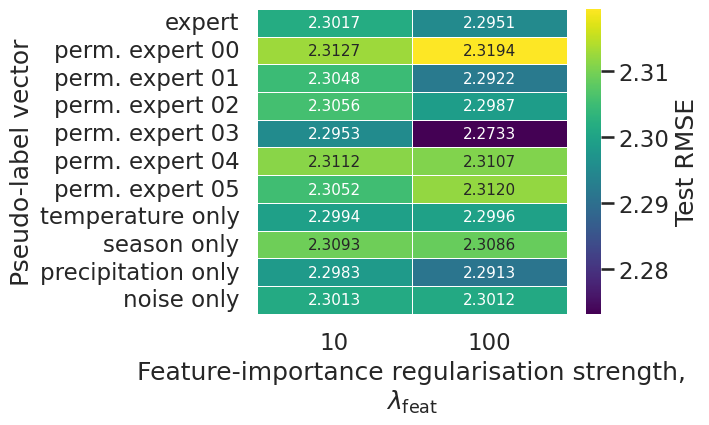

In [66]:
# Cell 13 - Heatmap of test RMSE across z vectors and lambda

# Optional: cleaner tick labels
rmse_plot = rmse_pivot.copy()
rmse_plot.columns = [f"{int(c)}" if float(c).is_integer() else f"{c:g}" for c in rmse_plot.columns]

# Optional: make row labels more presentation-friendly
pretty_index = {
    "expert": "expert",
    "perm_expert_00": "perm. expert 00",
    "perm_expert_01": "perm. expert 01",
    "perm_expert_02": "perm. expert 02",
    "perm_expert_03": "perm. expert 03",
    "perm_expert_04": "perm. expert 04",
    "perm_expert_05": "perm. expert 05",
    "temperature_only": "temperature only",
    "season_only": "season only",
    "precip_only": "precipitation only",
    "noise_only": "noise only",
}
rmse_plot.index = [pretty_index.get(idx, idx) for idx in rmse_plot.index]

plt.figure(figsize=(7.2, 4.6))
ax = sns.heatmap(
    rmse_plot,
    annot=True,
    fmt=".4f",
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Test RMSE"},
    annot_kws={"size": 11}
)

ax.set_title("")  # remove redundant title
ax.set_xlabel("Feature-importance regularisation strength,\n"
              r"$\lambda_{\mathrm{feat}}$")
ax.set_ylabel("Pseudo-label vector")

# Tidy tick labels
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.savefig("../docs/figures/ch5_z_rmse_heatmap.pdf", bbox_inches="tight")
plt.show()

In [67]:
# Cell 14 - Table version of the gate-cosine heatmap
gate_cos_pivot = (
    z_agg_df
    .pivot(index="z_name", columns="lambda_feat", values="gate_cosine_mean")
    .reindex(index=list(z_library.keys()), columns=lambda_values)
    .round(4)
)

display(gate_cos_pivot)

lambda_feat,10.0,100.0
z_name,,
expert,0.9434,0.9825
perm_expert_00,0.9359,0.9819
perm_expert_01,0.9389,0.9823
perm_expert_02,0.9373,0.9822
perm_expert_03,0.9237,0.9826
perm_expert_04,0.9366,0.9821
perm_expert_05,0.9187,0.9824
temperature_only,0.8611,0.9357
season_only,0.7552,0.9009


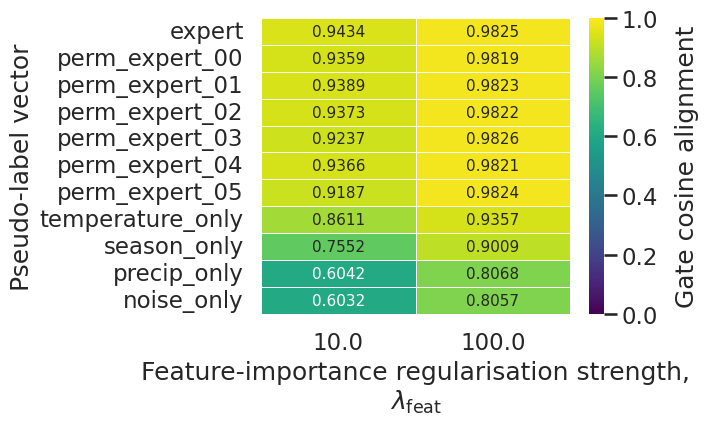

In [68]:
# Cell 15 - Heatmap of final gate cosine alignment across z vectors and lambda

plt.figure(figsize=(7.2, 4.6))
ax = sns.heatmap(
    gate_cos_pivot,
    annot=True,
    fmt=".4f",
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 11}
)

ax.set_title("")
ax.set_xlabel("Feature-importance regularisation strength,\n"
              r"$\lambda_{\mathrm{feat}}$")
ax.set_ylabel("Pseudo-label vector")

cbar = ax.collections[0].colorbar
if cbar is not None:
    cbar.set_label("Gate cosine alignment", rotation=90, labelpad=12)

plt.tight_layout()
plt.savefig("../docs/figures/ch5_z_gatecos_heatmap.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [69]:
# Cell 16 - Table version of the feature-loss-reduction heatmap
feat_reduction_pivot = (
    z_agg_df
    .pivot(index="z_name", columns="lambda_feat", values="feat_loss_reduction_frac_mean")
    .reindex(index=list(z_library.keys()), columns=lambda_values)
    .round(4)
)

display(feat_reduction_pivot)

lambda_feat,10.0,100.0
z_name,,
expert,0.7248,0.9139
perm_expert_00,0.6585,0.9126
perm_expert_01,0.6930,0.9136
perm_expert_02,0.6866,0.9131
perm_expert_03,0.6103,0.9154
perm_expert_04,0.6617,0.9133
perm_expert_05,0.5750,0.9142
temperature_only,0.6992,0.8620
season_only,0.6122,0.8586


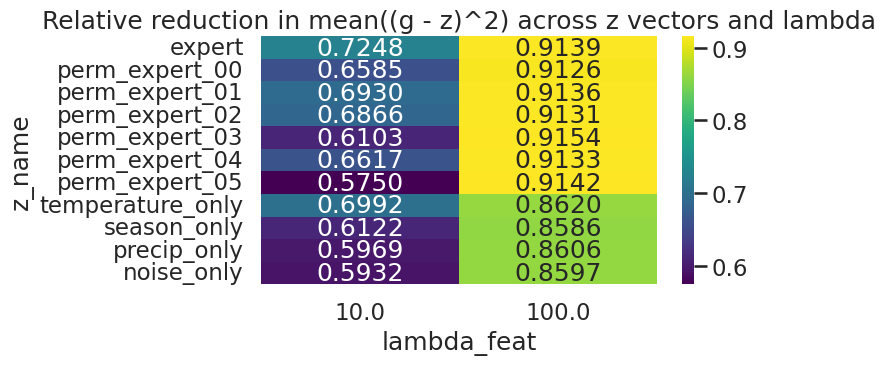

In [70]:
# Cell 17 - Heatmap of relative feature-loss reduction across z vectors and lambda
plt.figure(figsize=(8, max(4, 0.35 * len(z_library))))
sns.heatmap(feat_reduction_pivot, annot=True, fmt=".4f", cmap="viridis")
plt.title("Relative reduction in mean((g - z)^2) across z vectors and lambda")
plt.xlabel("lambda_feat")
plt.ylabel("z_name")
plt.tight_layout()
plt.show()

In [71]:
# Cell 18 - Table version of the gate-movement heatmap
gate_move_pivot = (
    z_agg_df
    .pivot(index="z_name", columns="lambda_feat", values="gate_move_l2_mean")
    .reindex(index=list(z_library.keys()), columns=lambda_values)
    .round(4)
)

display(gate_move_pivot)

lambda_feat,10.0,100.0
z_name,,
expert,0.5538,0.8079
perm_expert_00,0.4951,0.7936
perm_expert_01,0.5243,0.8048
perm_expert_02,0.5290,0.8019
perm_expert_03,0.4677,0.8133
perm_expert_04,0.4968,0.7945
perm_expert_05,0.4128,0.8052
temperature_only,0.7218,0.9500
season_only,0.6964,1.0478


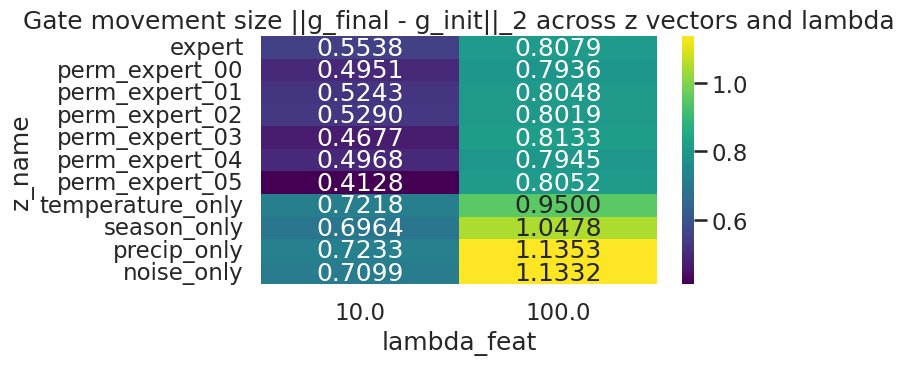

In [72]:
# Cell 19 - Heatmap of gate movement across z vectors and lambda
plt.figure(figsize=(8, max(4, 0.35 * len(z_library))))
sns.heatmap(gate_move_pivot, annot=True, fmt=".4f", cmap="viridis")
plt.title("Gate movement size ||g_final - g_init||_2 across z vectors and lambda")
plt.xlabel("lambda_feat")
plt.ylabel("z_name")
plt.tight_layout()
plt.show()

In [73]:
# Cell 20 - Compact summary table for the z sweep
summary_table = z_agg_df[
    [
        "z_family",
        "z_name",
        "lambda_feat",
        "test_rmse_mean",
        "test_rmse_std",
        "gate_cosine_mean",
        "gate_spearman_mean",
        "occ_cosine_mean",
        "occ_spearman_mean",
        "feat_loss_reduction_frac_mean",
        "gate_move_l2_mean",
        "rmse_rank_within_lambda",
        "gate_cos_rank_within_lambda",
        "occ_cos_rank_within_lambda",
    ]
].copy()

display(summary_table.round(4))

,z_family,z_name,lambda_feat,test_rmse_mean,test_rmse_std,gate_cosine_mean,gate_spearman_mean,occ_cosine_mean,occ_spearman_mean,feat_loss_reduction_frac_mean,gate_move_l2_mean,rmse_rank_within_lambda,gate_cos_rank_within_lambda,occ_cos_rank_within_lambda
0,expert,expert,10.0,2.3017,0.0147,0.9434,0.9165,0.7697,0.7856,0.7248,0.5538,5.0,1.0,1.0
1,permuted_expert,perm_expert_00,10.0,2.3127,0.0132,0.9359,0.9602,0.3764,-0.1600,0.6585,0.4951,11.0,5.0,8.0
2,permuted_expert,perm_expert_01,10.0,2.3048,0.0117,0.9389,0.8729,0.7246,0.4110,0.6930,0.5243,6.0,2.0,3.0
3,permuted_expert,perm_expert_02,10.0,2.3056,0.0114,0.9373,0.9820,0.6869,0.5310,0.6866,0.5290,8.0,3.0,4.0
4,permuted_expert,perm_expert_03,10.0,2.2953,0.0152,0.9237,0.7310,0.5546,0.1891,0.6103,0.4677,1.0,6.0,5.0
5,permuted_expert,perm_expert_04,10.0,2.3112,0.0129,0.9366,0.9820,0.4028,-0.0946,0.6617,0.4968,10.0,4.0,7.0
6,permuted_expert,perm_expert_05,10.0,2.3052,0.0128,0.9187,0.9165,0.4569,0.0109,0.5750,0.4128,7.0,7.0,6.0
7,structured,temperature_only,10.0,2.2994,0.0117,0.8611,0.8964,0.7689,0.7649,0.6992,0.7218,3.0,8.0,2.0
8,structured,season_only,10.0,2.3093,0.0121,0.7552,0.7906,0.2631,0.1581,0.6122,0.6964,9.0,9.0,9.0
9,structured,precip_only,10.0,2.2983,0.0158,0.6042,0.6124,0.0261,-0.0816,0.5969,0.7233,2.0,10.0,10.0


## Focused expert-vs-permuted comparison

The next table compares:

- the **expert prior**
- the **distribution of permuted-expert priors**

for each tested $ \lambda_{\text{feat}} $.

This is the most controlled comparison in the notebook, because the permuted priors use the **same values** as the expert prior and differ only in **which feature** receives each value.

In [74]:
# Cell 22 - Expert vs permuted-expert summary table
compare_rows = []

for lam in lambda_values:
    sub = z_agg_df[z_agg_df["lambda_feat"] == lam].copy()

    expert_row = sub[sub["z_name"] == "expert"].iloc[0]
    perm_rows = sub[sub["z_family"] == "permuted_expert"].copy()

    compare_rows.append(
        {
            "lambda_feat": float(lam),

            "expert_test_rmse": expert_row["test_rmse_mean"],
            "perm_test_rmse_mean": perm_rows["test_rmse_mean"].mean(),
            "perm_test_rmse_std": perm_rows["test_rmse_mean"].std(ddof=0),
            "n_perm_better_rmse": int((perm_rows["test_rmse_mean"] < expert_row["test_rmse_mean"]).sum()),

            "expert_gate_cos": expert_row["gate_cosine_mean"],
            "perm_gate_cos_mean": perm_rows["gate_cosine_mean"].mean(),
            "perm_gate_cos_std": perm_rows["gate_cosine_mean"].std(ddof=0),
            "n_perm_better_gate_cos": int((perm_rows["gate_cosine_mean"] > expert_row["gate_cosine_mean"]).sum()),

            "expert_occ_cos": expert_row["occ_cosine_mean"],
            "perm_occ_cos_mean": perm_rows["occ_cosine_mean"].mean(),
            "perm_occ_cos_std": perm_rows["occ_cosine_mean"].std(ddof=0),
            "n_perm_better_occ_cos": int((perm_rows["occ_cosine_mean"] > expert_row["occ_cosine_mean"]).sum()),

            "expert_feat_reduction": expert_row["feat_loss_reduction_frac_mean"],
            "perm_feat_reduction_mean": perm_rows["feat_loss_reduction_frac_mean"].mean(),
            "perm_feat_reduction_std": perm_rows["feat_loss_reduction_frac_mean"].std(ddof=0),

            "expert_gate_move_l2": expert_row["gate_move_l2_mean"],
            "perm_gate_move_l2_mean": perm_rows["gate_move_l2_mean"].mean(),
            "perm_gate_move_l2_std": perm_rows["gate_move_l2_mean"].std(ddof=0),

            "expert_rmse_rank_within_lambda": expert_row["rmse_rank_within_lambda"],
            "expert_gate_cos_rank_within_lambda": expert_row["gate_cos_rank_within_lambda"],
            "expert_occ_cos_rank_within_lambda": expert_row["occ_cos_rank_within_lambda"],
        }
    )

expert_vs_perm_table = pd.DataFrame(compare_rows)
display(expert_vs_perm_table.round(4))

,lambda_feat,expert_test_rmse,perm_test_rmse_mean,perm_test_rmse_std,n_perm_better_rmse,expert_gate_cos,perm_gate_cos_mean,perm_gate_cos_std,n_perm_better_gate_cos,expert_occ_cos,perm_occ_cos_mean,perm_occ_cos_std,n_perm_better_occ_cos,expert_feat_reduction,perm_feat_reduction_mean,perm_feat_reduction_std,expert_gate_move_l2,perm_gate_move_l2_mean,perm_gate_move_l2_std,expert_rmse_rank_within_lambda,expert_gate_cos_rank_within_lambda,expert_occ_cos_rank_within_lambda
0,10.0,2.3017,2.3058,0.0056,1,0.9434,0.9319,0.0077,0,0.7697,0.5337,0.1342,0,0.7248,0.6475,0.0420,0.5538,0.4876,0.0391,5.0,1.0,1.0
1,100.0,2.2951,2.3011,0.0153,2,0.9825,0.9822,0.0002,1,0.7329,0.5556,0.1133,0,0.9139,0.9137,0.0009,0.8079,0.8022,0.0067,4.0,2.0,2.0


## Selected-run occlusion analysis

The next cells inspect a small set of exact trained runs using the supplementary occlusion metric.

This section is useful for:
- comparing the expert prior to a permuted prior and a noise-only prior,
- comparing baseline and gated models at the function level,
- and visualizing the normalized global occlusion importance profile by feature.

In [75]:
# Cell 23 - Table of final mean gate profiles at the selected lambda
gate_profile_cols = ["z_family", "z_name"] + [f"g_final_{name}_mean" for name in feature_cols]

gate_profile_table = (
    z_agg_df[z_agg_df["lambda_feat"] == selected_lambda_for_profiles][gate_profile_cols]
    .copy()
    .sort_values(["z_family", "z_name"])
)

gate_profile_table = gate_profile_table.rename(
    columns={f"g_final_{name}_mean": name for name in feature_cols}
)

display(gate_profile_table.round(4))

,z_family,z_name,tmin,tavg,tmax,prcp,dayofyear_sin,dayofyear_cos,rand_noise
11,expert,expert,0.7012,0.9011,0.8968,0.4161,0.3452,0.3633,0.2705
12,permuted_expert,perm_expert_00,0.9053,0.3841,0.4367,0.2735,0.3463,0.7004,0.9155
13,permuted_expert,perm_expert_01,0.3565,0.9005,0.3648,0.2737,0.9111,0.7019,0.4116
14,permuted_expert,perm_expert_02,0.9053,0.8998,0.4272,0.2734,0.6981,0.3643,0.3481
15,permuted_expert,perm_expert_03,0.3561,0.7088,0.2750,0.9161,0.3468,0.9002,0.4120
16,permuted_expert,perm_expert_04,0.9053,0.4488,0.3724,0.2735,0.3462,0.7003,0.9155
17,permuted_expert,perm_expert_05,0.3531,0.4382,0.8957,0.9162,0.3452,0.2745,0.7001
18,structured,temperature_only,0.7009,0.9009,0.8967,0.2733,0.2676,0.2745,0.2703
19,structured,season_only,0.2692,0.2855,0.2808,0.2730,0.9110,0.8997,0.2698
20,structured,precip_only,0.2696,0.2849,0.2793,0.9163,0.2668,0.2728,0.2696


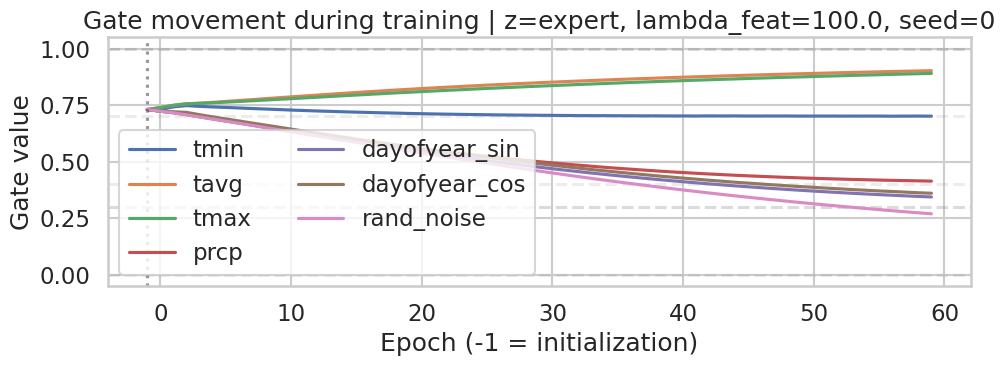

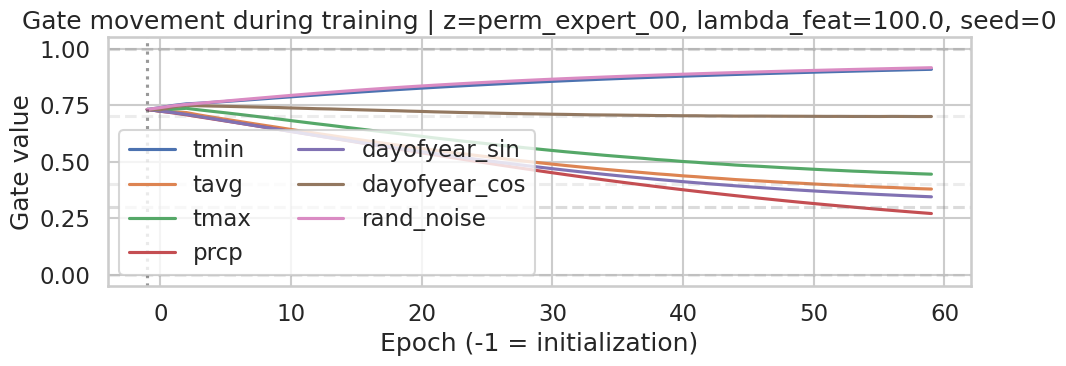

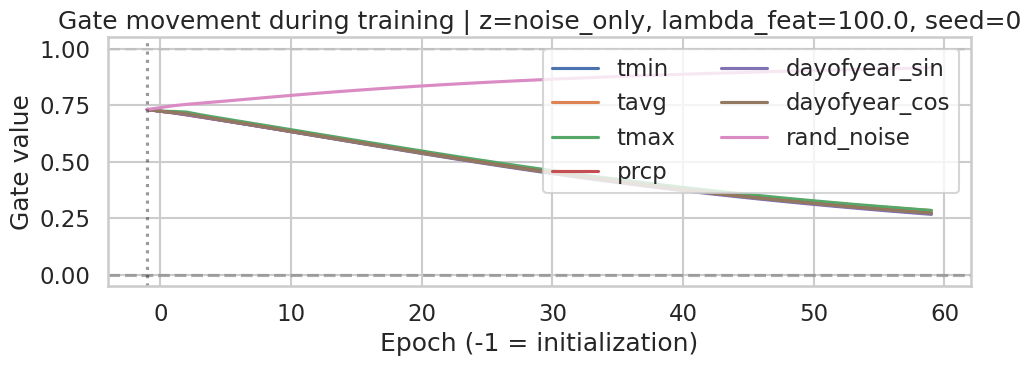

In [76]:
# Cell 24 - Plot gate trajectories for selected z vectors
# Here, epoch = -1 denotes the true initialization before any optimization step.
for z_name in selected_z_names:
    sub = z_history_df[
        (z_history_df["z_name"] == z_name)
        & (z_history_df["lambda_feat"] == selected_lambda_for_profiles)
        & (z_history_df["seed"] == selected_seed_for_trajectories)
        & (z_history_df["epoch"] >= -1)
    ].copy()

    plt.figure(figsize=(10, 4))
    for feature_name, z_val in zip(feature_cols, z_library[z_name]):
        plt.plot(sub["epoch"], sub[f"g_{feature_name}"], label=feature_name)
        plt.axhline(z_val, linestyle="--", alpha=0.15, color="gray")

    plt.axvline(-1.0, linestyle=":", color="black", alpha=0.4)
    plt.title(
        f"Gate movement during training | z={z_name}, "
        f"lambda_feat={selected_lambda_for_profiles}, seed={selected_seed_for_trajectories}"
    )
    plt.xlabel("Epoch (-1 = initialization)")
    plt.ylabel("Gate value")
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()

In [77]:
# Cell 25 - Table version of the selected gate-trajectory plots
selected_features_for_traj = ["tmin", "tavg", "tmax", "prcp", "rand_noise"]

def gate_cos_to_z_from_row(row, feature_names, z_vec):
    g = np.array([row[f"g_{name}"] for name in feature_names], dtype=float)
    denom = np.linalg.norm(g) * np.linalg.norm(z_vec)
    if denom == 0:
        return np.nan
    return float(np.dot(g, z_vec) / denom)

traj_summary_frames = []

for z_name in selected_z_names:
    sub = z_history_df[
        (z_history_df["z_name"] == z_name) &
        (z_history_df["lambda_feat"] == float(selected_lambda_for_profiles)) &
        (z_history_df["seed"] == float(selected_seed_for_trajectories))
    ].copy()

    milestone_epochs = sorted(set([-1, 0, 1, 2, 5, 10, 20, 30, int(sub["epoch"].max())]))
    sub = sub[sub["epoch"].isin(milestone_epochs)].copy()

    z_cur = z_library[z_name].astype(float)

    sub["gate_l2_to_z"] = sub.apply(
        lambda r: float(
            np.linalg.norm(
                np.array([r[f"g_{name}"] for name in feature_cols], dtype=float) - z_cur
            )
        ),
        axis=1,
    )

    sub["gate_cos_to_z"] = sub.apply(
        lambda r: gate_cos_to_z_from_row(r, feature_cols, z_cur),
        axis=1,
    )

    keep_cols = (
        ["z_name", "z_family", "lambda_feat", "seed", "epoch", "gate_l2_to_z", "gate_cos_to_z"]
        + [f"g_{name}" for name in selected_features_for_traj]
    )

    traj_summary_frames.append(
        sub[keep_cols].sort_values("epoch")
    )

z_traj_milestone_table = pd.concat(traj_summary_frames, ignore_index=True).round(4)

display(z_traj_milestone_table)

,z_name,z_family,lambda_feat,seed,epoch,gate_l2_to_z,gate_cos_to_z,g_tmin,g_tavg,g_tmax,g_prcp,g_rand_noise
0,expert,expert,100.0,0.0,-1.0,1.0776,0.8313,0.7311,0.7311,0.7311,0.7311,0.7311
1,expert,expert,100.0,0.0,0.0,1.0597,0.8363,0.7303,0.7391,0.7395,0.7233,0.7232
2,expert,expert,100.0,0.0,1.0,1.0446,0.8418,0.7426,0.7489,0.7498,0.7170,0.7159
3,expert,expert,100.0,0.0,2.0,1.0290,0.8464,0.7481,0.7560,0.7564,0.7084,0.7071
4,expert,expert,100.0,0.0,5.0,0.9741,0.8579,0.7400,0.7665,0.7634,0.6805,0.6793
5,expert,expert,100.0,0.0,10.0,0.8840,0.8776,0.7284,0.7867,0.7787,0.6369,0.6326
6,expert,expert,100.0,0.0,20.0,0.7128,0.9142,0.7123,0.8236,0.8101,0.5573,0.5382
7,expert,expert,100.0,0.0,30.0,0.5682,0.9429,0.7049,0.8519,0.8366,0.4947,0.4502
8,expert,expert,100.0,0.0,59.0,0.3162,0.9825,0.7014,0.9026,0.8905,0.4142,0.2696
9,perm_expert_00,permuted_expert,100.0,0.0,-1.0,1.0776,0.8313,0.7311,0.7311,0.7311,0.7311,0.7311


In [78]:
# Cell 26 - SHAP imports
import importlib
import json

from IPython.display import display

shap = importlib.import_module("shap")

# Placeholders for notebook static analysis / Pylance
shap_run_df: pd.DataFrame = pd.DataFrame()
shap_feature_df: pd.DataFrame = pd.DataFrame()
shap_global_pivot: pd.DataFrame = pd.DataFrame()
shap_store: dict[str, dict[str, object]] = {}

baseline_shap_feature_df: pd.DataFrame = pd.DataFrame()
baseline_occ_feature_df: pd.DataFrame = pd.DataFrame()
baseline_vs_z_df: pd.DataFrame = pd.DataFrame()
baseline_occ_vs_z_df: pd.DataFrame = pd.DataFrame()
baseline_vs_gated_df: pd.DataFrame = pd.DataFrame()
baseline_vs_gated_feature_df: pd.DataFrame = pd.DataFrame()
baseline_vs_gated_occ_df: pd.DataFrame = pd.DataFrame()
combined_shap_pivot: pd.DataFrame = pd.DataFrame()
combined_occ_pivot: pd.DataFrame = pd.DataFrame()

baseline_record: dict[str, Any] = {}
baseline_shap_vector: np.ndarray = np.array([], dtype=np.float64)
baseline_occ_imp: np.ndarray = np.array([], dtype=np.float64)

In [79]:
# Cell 27 - compute baseline SHAP using the same setup as the gated SHAP runs
shap_results_dir = results_dir / "shap"
shap_results_dir.mkdir(parents=True, exist_ok=True)

if RUN_SHAP:
    baseline_record, baseline_hist_df, baseline_model = run_baseline_experiment_for_shap(
        seed=selected_shap_seed,
        return_model=True,
    )

    X_background, _ = sample_rows(
        data.X_train,
        n=shap_background_size,
        seed=selected_shap_seed,
    )

    if shap_explain_split == "test":
        X_explain_baseline = data.X_test
    elif shap_explain_split == "val":
        X_explain_baseline = data.X_val
    else:
        raise ValueError("shap_explain_split must be either 'test' or 'val'")

    baseline_shap_result = compute_shap_values(
        model=baseline_model,
        X_background=X_background,
        X_explain=X_explain_baseline,
        device=device,
        method=shap_method_preference,
        use_gate=False,   # explicit for baseline
    )

    baseline_shap_feature_df = make_global_shap_table(
        baseline_shap_result.shap_values,
        feature_cols,
    )

    baseline_shap_vector = baseline_shap_result.importance_mean_abs_norm.astype(np.float64)

    print("Baseline predictive metrics:")
    display(pd.DataFrame([baseline_record]).round(4))

    print("Baseline global SHAP table:")
    display(baseline_shap_feature_df.round(4))

else:
    print("RUN_SHAP=False -> baseline SHAP will be loaded from cached files later.")

RUN_SHAP=False -> baseline SHAP will be loaded from cached files later.


In [80]:
# Cell 27a - compute baseline occlusion importance on the same evaluation split

if RUN_SHAP:
    if shap_explain_split == "test":
        X_occ_eval = data.X_test
    elif shap_explain_split == "val":
        X_occ_eval = data.X_val
    else:
        raise ValueError("shap_explain_split must be either 'test' or 'val'")

    baseline_occ_imp = compute_occlusion_importance(
        model=baseline_model,
        X=X_occ_eval,
        device=device,
        batch_size=config.eval_batch_size,
        baseline_value=0.0,
        use_gate=None,
    )

    baseline_occ_feature_df = pd.DataFrame(
        {
            "feature": feature_cols,
            "baseline_occ_importance": baseline_occ_imp,
        }
    ).sort_values("baseline_occ_importance", ascending=False).reset_index(drop=True)

    print("Baseline global occlusion importance:")
    display(baseline_occ_feature_df.round(4))

else:
    print("RUN_SHAP=False -> baseline occlusion will be loaded from cached files later.")

RUN_SHAP=False -> baseline occlusion will be loaded from cached files later.


In [81]:
# Cell 27b - exact selected-run occlusion summary table
selected_occ_run_rows = []

for z_name in selected_shap_z_names:
    run_row = z_sweep_df[
        (z_sweep_df["z_name"] == z_name)
        & (z_sweep_df["lambda_feat"] == float(selected_shap_lambda))
        & (z_sweep_df["seed"] == float(selected_shap_seed))
    ].iloc[0]

    selected_occ_run_rows.append(
        {
            "z_name": z_name,
            "z_family": z_family_of(z_name),
            "lambda_feat": float(selected_shap_lambda),
            "seed": int(selected_shap_seed),
            "test_rmse": float(run_row["test_rmse"]),
            "gate_cos": float(run_row["gate_cos_final"]),
            "gate_spearman": float(run_row["gate_spearman_final"]),
            "occ_cos": float(run_row["occ_cos_final"]),
            "occ_spearman": float(run_row["occ_spearman_final"]),
            "feat_loss_reduction_frac": float(run_row["feat_loss_reduction_frac"]),
            "gate_move_l2": float(run_row["gate_move_l2"]),
        }
    )

selected_occ_run_df = pd.DataFrame(selected_occ_run_rows)
display(selected_occ_run_df.round(4))

,z_name,z_family,lambda_feat,seed,test_rmse,gate_cos,gate_spearman,occ_cos,occ_spearman,feat_loss_reduction_frac,gate_move_l2
0,expert,expert,100.0,0,2.2984,0.9825,0.9820,0.7687,0.8365,0.9139,0.8100
1,perm_expert_00,permuted_expert,100.0,0,2.3193,0.9824,0.9820,0.4264,-0.3819,0.9147,0.7958
2,noise_only,structured,100.0,0,2.3064,0.8055,0.6124,0.0035,-0.4082,0.8595,1.1327


In [82]:
# Cell 27ba - Load cached SHAP outputs when RUN_SHAP=False

shap_results_dir = results_dir / "shap"

if not RUN_SHAP:
    # Main SHAP tables
    shap_run_df = pd.read_csv(shap_results_dir / "shap_run_summary.csv")
    shap_feature_df = pd.read_csv(shap_results_dir / "shap_feature_importance.csv")
    shap_global_pivot = pd.read_csv(
        shap_results_dir / "shap_global_importance_pivot.csv",
        index_col=0,
    )

    # Baseline artifacts
    baseline_record_df = pd.read_csv(shap_results_dir / "baseline_record.csv")
    baseline_record = baseline_record_df.iloc[0].to_dict()

    baseline_shap_feature_df = pd.read_csv(
        shap_results_dir / "baseline_shap_feature_importance.csv"
    )
    baseline_occ_feature_df = pd.read_csv(
        shap_results_dir / "baseline_occlusion_importance.csv"
    )

    baseline_shap_vector = pd.read_csv(
        shap_results_dir / "baseline_shap_vector.csv"
    )["baseline_shap_norm"].to_numpy(dtype=np.float64)

    baseline_occ_imp = pd.read_csv(
        shap_results_dir / "baseline_occ_vector.csv"
    )["baseline_occ_importance"].to_numpy(dtype=np.float64)

    # Rebuild lightweight shap_store from saved artifacts
    shap_store = {}

    for z_name in selected_shap_z_names:
        run_id = f"z={z_name}|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"
        safe_name = (
            run_id.replace("|", "__")
            .replace("=", "_")
            .replace(".", "p")
        )
        run_dir = shap_results_dir / safe_name

        with open(run_dir / "meta.json", "r") as fh:
            meta = json.load(fh)

        X_explain = np.load(run_dir / "X_explain.npy")
        shap_values = np.load(run_dir / "shap_values.npy")
        z = np.load(run_dir / "z.npy")
        z_norm = np.load(run_dir / "z_norm.npy")
        g_init = np.load(run_dir / "g_init.npy")
        g_final = np.load(run_dir / "g_final.npy")
        shap_importance_mean_abs = np.load(run_dir / "shap_importance_mean_abs.npy")
        shap_importance_mean_abs_norm = np.load(run_dir / "shap_importance_mean_abs_norm.npy")

        shap_store[run_id] = {
            "run_id": run_id,
            "model": None,
            "X_explain": X_explain,
            "X_explain_df": pd.DataFrame(X_explain, columns=feature_cols),
            "z": z,
            "z_norm": z_norm,
            "g_init": g_init,
            "g_final": g_final,
            "shap_values": shap_values,
            "shap_expected_value": float(meta["expected_value"]),
            "shap_importance_mean_abs": shap_importance_mean_abs,
            "shap_importance_mean_abs_norm": shap_importance_mean_abs_norm,
        }

    print("Loaded cached SHAP artifacts from:", shap_results_dir)
    print("shap_run_df shape:", shap_run_df.shape)
    print("shap_feature_df shape:", shap_feature_df.shape)
    print("baseline_shap_vector length:", len(baseline_shap_vector))
    print("baseline_occ_imp length:", len(baseline_occ_imp))
    print("Loaded runs into shap_store:", list(shap_store.keys()))

Loaded cached SHAP artifacts from: <project root>/results/feature_importance_basic/z_sweep_basic/shap
shap_run_df shape: (3, 19)
shap_feature_df shape: (21, 12)
baseline_shap_vector length: 7
baseline_occ_imp length: 7
Loaded runs into shap_store: ['z=expert|lambda=100|seed=0', 'z=perm_expert_00|lambda=100|seed=0', 'z=noise_only|lambda=100|seed=0']


In [83]:
# Cell 27c - table version of normalized global occlusion importance by feature
occ_rows = []

# baseline row first
occ_rows.append(
    pd.Series(
        baseline_occ_imp,
        index=feature_cols,
        name="baseline",
    )
)

# selected gated rows
for z_name in selected_shap_z_names:
    run_row = z_sweep_df[
        (z_sweep_df["z_name"] == z_name)
        & (z_sweep_df["lambda_feat"] == float(selected_shap_lambda))
        & (z_sweep_df["seed"] == float(selected_shap_seed))
    ].iloc[0]

    occ_vec = np.array(
        [run_row[f"occ_final_{name}"] for name in feature_cols],
        dtype=np.float64,
    )

    occ_rows.append(
        pd.Series(
            occ_vec,
            index=feature_cols,
            name=z_name,
        )
    )

combined_occ_pivot = pd.DataFrame(occ_rows).round(4)
display(combined_occ_pivot)

,tmin,tavg,tmax,prcp,dayofyear_sin,dayofyear_cos,rand_noise
baseline,0.0050,0.4362,0.3057,0.0112,0.0226,0.2179,0.0014
expert,0.0268,0.6531,0.1773,0.0073,0.0018,0.1332,0.0005
perm_expert_00,0.0073,0.4043,0.3773,0.0076,0.0029,0.1984,0.0022
noise_only,0.0036,0.4288,0.3730,0.0095,0.0016,0.1813,0.0021


## Heatmap of normalized global occlusion importance

The following heatmap provides a compact feature-level comparison between:
- the baseline model,
- the expert-prior gated model,
- a permuted-expert prior,
- and a noise-only prior.

Each row is a normalized global occlusion importance vector, so the entries in each row sum to approximately 1.

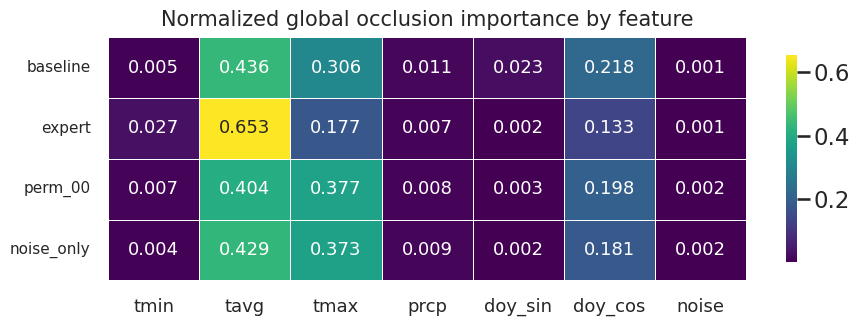

In [84]:
# Cell 27d - heatmap of normalized global occlusion importance by feature
plot_df = combined_occ_pivot.copy()
plot_df = plot_df.rename(
    columns={
        "dayofyear_sin": "doy_sin",
        "dayofyear_cos": "doy_cos",
        "rand_noise": "noise",
    },
    index={"perm_expert_00": "perm_00"},
)

fig, ax = plt.subplots(figsize=(9.5, 3.6))

sns.heatmap(
    plot_df,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 13},
    cbar_kws={"shrink": 0.85},
    ax=ax,
)

ax.set_title("Normalized global occlusion importance by feature", fontsize=15, pad=8)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=13, rotation=0)
ax.tick_params(axis="y", labelsize=11, rotation=0)

plt.tight_layout()
plt.savefig("../docs/figures/ch5_occ_heatmap.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [85]:
# Cell 27e - baseline occlusion alignment to selected z vectors
baseline_occ_vs_z_rows = []

for z_name in selected_shap_z_names:
    z_np_cur = z_library[z_name].astype(np.float64)
    z_norm = z_np_cur / (z_np_cur.sum() + 1e-8)

    a = compute_alignment_metrics(baseline_occ_imp, z_norm)

    baseline_occ_vs_z_rows.append(
        {
            "z_name": z_name,
            "z_family": z_family_of(z_name),
            "baseline_occ_l2_to_z": a.l2_distance,
            "baseline_occ_cos_to_z": a.cosine_similarity,
            "baseline_occ_spearman_to_z": a.spearman_rank_corr,
        }
    )

baseline_occ_vs_z_df = pd.DataFrame(baseline_occ_vs_z_rows)
display(baseline_occ_vs_z_df.round(4))

,z_name,z_family,baseline_occ_l2_to_z,baseline_occ_cos_to_z,baseline_occ_spearman_to_z
0,expert,expert,0.3070,0.8482,0.6547
1,perm_expert_00,permuted_expert,0.5587,0.4322,-0.4728
2,noise_only,structured,1.1528,0.0025,-0.6124


In [86]:
# Cell 27f - run-level baseline vs gated occlusion comparison
baseline_vs_gated_occ_rows = []

for z_name in selected_shap_z_names:
    run_row = z_sweep_df[
        (z_sweep_df["z_name"] == z_name)
        & (z_sweep_df["lambda_feat"] == float(selected_shap_lambda))
        & (z_sweep_df["seed"] == float(selected_shap_seed))
    ].iloc[0]

    gated_occ_vec = np.array(
        [run_row[f"occ_final_{name}"] for name in feature_cols],
        dtype=np.float64,
    )

    comp = compute_alignment_metrics(baseline_occ_imp, gated_occ_vec)

    baseline_vs_gated_occ_rows.append(
        {
            "z_name": z_name,
            "z_family": z_family_of(z_name),
            "baseline_test_rmse": float(baseline_record["test_rmse"]),
            "gated_test_rmse": float(run_row["test_rmse"]),
            "occ_l2_baseline_vs_gated": comp.l2_distance,
            "occ_cos_baseline_vs_gated": comp.cosine_similarity,
            "occ_spearman_baseline_vs_gated": comp.spearman_rank_corr,
            "gated_occ_cos_to_z": float(run_row["occ_cos_final"]),
            "gated_occ_spearman_to_z": float(run_row["occ_spearman_final"]),
        }
    )

baseline_vs_gated_occ_df = pd.DataFrame(baseline_vs_gated_occ_rows)
display(baseline_vs_gated_occ_df.round(4))

,z_name,z_family,baseline_test_rmse,gated_test_rmse,occ_l2_baseline_vs_gated,occ_cos_baseline_vs_gated,occ_spearman_baseline_vs_gated,gated_occ_cos_to_z,gated_occ_spearman_to_z
0,expert,expert,2.3235,2.2984,0.2677,0.9263,0.8571,0.7687,0.8365
1,perm_expert_00,permuted_expert,2.3235,2.3193,0.0833,0.9900,0.8929,0.4264,-0.3819
2,noise_only,structured,2.3235,2.3064,0.0798,0.9914,0.7857,0.0035,-0.4082


,feature,expert_z_norm,expert_shap_norm,expert_occ_norm
0,tmin,0.1892,0.0880,0.0268
1,tavg,0.2703,0.4488,0.6531
2,tmax,0.2703,0.1998,0.1773
3,prcp,0.1081,0.0277,0.0073
4,dayofyear_sin,0.0811,0.0143,0.0018
5,dayofyear_cos,0.0811,0.2149,0.1332
6,rand_noise,0.0000,0.0065,0.0005


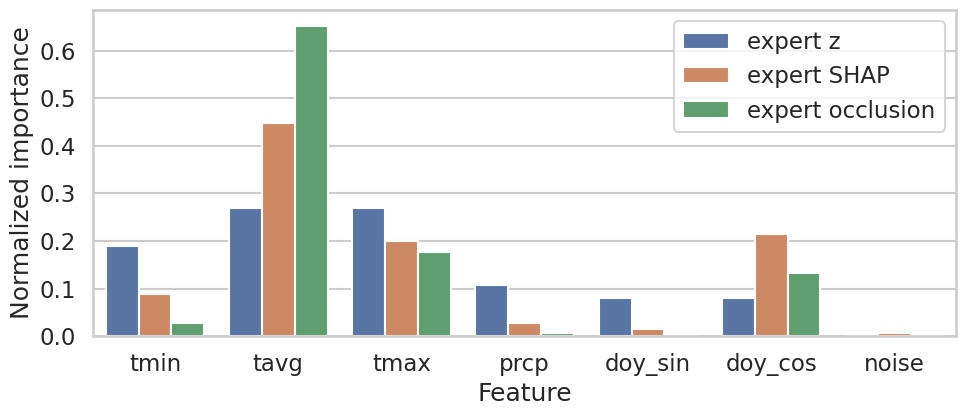

In [105]:
# Cell 27g - Direct comparison: expert z vs expert SHAP vs expert occlusion

expert_run_id = f"z=expert|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"
assert expert_run_id in shap_store, f"Missing SHAP artifact for {expert_run_id}"

# expert z
expert_z = z_library["expert"].astype(np.float64)
expert_z_norm = expert_z / (expert_z.sum() + 1e-8)

# expert SHAP
expert_shap_norm = np.asarray(
    shap_store[expert_run_id]["shap_importance_mean_abs_norm"],
    dtype=np.float64,
)

# expert occlusion from the stored z-sweep row
expert_run_row = z_sweep_df[
    (z_sweep_df["z_name"] == "expert")
    & (z_sweep_df["lambda_feat"] == float(selected_shap_lambda))
    & (z_sweep_df["seed"] == float(selected_shap_seed))
].iloc[0]

expert_occ_norm = np.array(
    [expert_run_row[f"occ_final_{name}"] for name in feature_cols],
    dtype=np.float64,
)

expert_compare_df = pd.DataFrame(
    {
        "feature": feature_cols,
        "expert_z_norm": expert_z_norm,
        "expert_shap_norm": expert_shap_norm,
        "expert_occ_norm": expert_occ_norm,
    }
)

display(expert_compare_df.round(4))

plot_df = expert_compare_df.melt(
    id_vars="feature",
    value_vars=["expert_z_norm", "expert_shap_norm", "expert_occ_norm"],
    var_name="profile",
    value_name="importance",
)

profile_label_map = {
    "expert_z_norm": "expert z",
    "expert_shap_norm": "expert SHAP",
    "expert_occ_norm": "expert occlusion",
}
plot_df["profile"] = plot_df["profile"].map(profile_label_map)

feature_label_map = {
    "tmin": "tmin",
    "tavg": "tavg",
    "tmax": "tmax",
    "prcp": "prcp",
    "dayofyear_sin": "doy_sin",
    "dayofyear_cos": "doy_cos",
    "rand_noise": "noise",
}
plot_df["feature_pretty"] = plot_df["feature"].map(feature_label_map)

plt.figure(figsize=(10, 4.5))
sns.barplot(
    data=plot_df,
    x="feature_pretty",
    y="importance",
    hue="profile",
)
#plt.title(f"Expert pseudo-label vs SHAP vs occlusion\n"f"(lambda_feat={selected_shap_lambda:g}, seed={selected_shap_seed})")
plt.xlabel("Feature")
plt.ylabel("Normalized importance")
plt.legend(title="")
plt.tight_layout()
plt.savefig("../docs/figures/ch5_expert_z_vs_shap_occ.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [88]:
# Cell 28 - Compute SHAP for the exact trained models selected from the main sweep

if RUN_SHAP:
    shap_run_records = []
    shap_feature_frames = []
    shap_store = {}

    for z_name in selected_shap_z_names:
        run_id = f"z={z_name}|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"
        assert run_id in selected_model_store, f"Missing stored model for run_id={run_id}"

        model = selected_model_store[run_id]
        z_np_cur = z_library[z_name].astype(np.float32)
        z_norm = z_np_cur.astype(np.float64) / (z_np_cur.sum() + 1e-8)

        run_row = z_sweep_df[
            (z_sweep_df["z_name"] == z_name)
            & (z_sweep_df["lambda_feat"] == float(selected_shap_lambda))
            & (z_sweep_df["seed"] == float(selected_shap_seed))
        ].iloc[0]

        g_final = model.g.detach().cpu().numpy()

        hist_init_row = z_history_df[
            (z_history_df["z_name"] == z_name)
            & (z_history_df["lambda_feat"] == float(selected_shap_lambda))
            & (z_history_df["seed"] == float(selected_shap_seed))
            & (z_history_df["epoch"] == -1.0)
        ].iloc[0]

        g_init = np.array([hist_init_row[f"g_{name}"] for name in feature_cols], dtype=np.float32)

        X_background, _ = sample_rows(data.X_train, n=shap_background_size, seed=selected_shap_seed)

        if shap_explain_split == "test":
            X_explain = data.X_test
        elif shap_explain_split == "val":
            X_explain = data.X_val
        else:
            raise ValueError("shap_explain_split must be either 'test' or 'val'")

        shap_result = compute_shap_values(
            model=model,
            X_background=X_background,
            X_explain=X_explain,
            device=device,
            method=shap_method_preference,
            use_gate=True,
        )

        shap_align = compute_shap_alignment(shap_result.shap_values, z_np_cur)

        run_record = {
            "run_id": run_id,
            "z_family": z_family_of(z_name),
            "z_name": z_name,
            "lambda_feat": float(selected_shap_lambda),
            "seed": int(selected_shap_seed),

            "test_mse": float(run_row["test_mse"]),
            "test_rmse": float(run_row["test_rmse"]),
            "test_mae": float(run_row["test_mae"]),

            "gate_l2": float(run_row["gate_l2_final"]),
            "gate_cos": float(run_row["gate_cos_final"]),
            "gate_spearman": float(run_row["gate_spearman_final"]),

            "feat_loss_init": float(run_row["feat_loss_init"]),
            "feat_loss_final": float(run_row["feat_loss_final"]),
            "feat_loss_reduction_frac": float(run_row["feat_loss_reduction_frac"]),
            "gate_move_l2": float(run_row["gate_move_l2"]),

            "shap_l2": shap_align.l2_distance,
            "shap_cos": shap_align.cosine_similarity,
            "shap_spearman": shap_align.spearman_rank_corr,
            "shap_expected_value": float(shap_result.expected_value),
        }

        feature_table = make_global_shap_table(shap_result.shap_values, feature_cols)

        feature_rows = []
        for _, row in feature_table.iterrows():
            feature_name = str(row["feature"])
            j = feature_cols.index(feature_name)

            feature_rows.append(
                {
                    "run_id": run_id,
                    "z_family": z_family_of(z_name),
                    "z_name": z_name,
                    "lambda_feat": float(selected_shap_lambda),
                    "seed": int(selected_shap_seed),
                    "feature": feature_name,
                    "mean_abs_shap": float(row["mean_abs_shap"]),
                    "mean_abs_shap_norm": float(row["mean_abs_shap_norm"]),
                    "z": float(z_np_cur[j]),
                    "z_norm": float(z_norm[j]),
                    "g_final": float(g_final[j]),
                    "diff_norm_shap_minus_z": float(row["mean_abs_shap_norm"] - z_norm[j]),
                }
            )

        shap_run_records.append(run_record)
        shap_feature_frames.append(pd.DataFrame(feature_rows))

        shap_store[run_id] = {
            "run_id": run_id,
            "model": model,
            "X_explain": np.asarray(X_explain, dtype=np.float32),
            "X_explain_df": pd.DataFrame(X_explain, columns=feature_cols),
            "z": z_np_cur.astype(np.float32),
            "z_norm": z_norm.astype(np.float64),
            "g_init": g_init.astype(np.float32),
            "g_final": g_final.astype(np.float32),
            "shap_values": shap_result.shap_values.astype(np.float64),
            "shap_expected_value": float(shap_result.expected_value),
            "shap_importance_mean_abs": shap_result.importance_mean_abs.astype(np.float64),
            "shap_importance_mean_abs_norm": shap_result.importance_mean_abs_norm.astype(np.float64),
        }

    shap_run_df = (
        pd.DataFrame(shap_run_records)
        .sort_values(["z_family", "z_name"])
        .reset_index(drop=True)
    )

    shap_feature_df = pd.concat(shap_feature_frames, ignore_index=True)

    print(f"Computed SHAP for {len(shap_run_df)} exact stored main-run models.")
    display(shap_run_df.round(4))

else:
    print("RUN_SHAP=False -> selected-run SHAP will be loaded from cached files later.")

RUN_SHAP=False -> selected-run SHAP will be loaded from cached files later.


## SHAP summary tables

The next tables show:

1. **run-level SHAP summaries**
2. **feature-level SHAP importances**

For each selected run, the SHAP-based global importance vector is obtained by averaging absolute SHAP values across the explained samples and then normalizing.

This lets us compare:

- **prediction quality**
- **gate alignment to $z$**
- **SHAP alignment to $z$**

## Meaning of the SHAP alignment metrics

For each selected trained model, we compute a **global SHAP importance vector** by averaging the absolute SHAP values across the explained samples:

$$
s_j = \frac{1}{n}\sum_{i=1}^n |\phi_{ij}|.
$$

This vector is then normalized to sum to 1 and compared to the pseudo-label vector $z$.

### SHAP L2 distance
This is the Euclidean distance between normalized global SHAP importance and normalized $z$:

$$
\| s^{\mathrm{norm}} - z^{\mathrm{norm}} \|_2.
$$

- Smaller is better.
- It measures overall numerical mismatch between the SHAP importance profile and the pseudo-label profile.

### SHAP cosine similarity
This is the cosine similarity between normalized global SHAP importance and normalized $z$:

$$
\frac{\langle s^{\mathrm{norm}}, z^{\mathrm{norm}} \rangle}
{\|s^{\mathrm{norm}}\|_2 \|z^{\mathrm{norm}}\|_2}.
$$

- Larger is better.
- It measures whether SHAP and $z$ emphasize the same features overall.
- In this notebook, **SHAP cosine similarity is the easiest scalar summary to interpret**.

### SHAP Spearman rank correlation
This is the Spearman rank correlation between the SHAP-based feature ranking and the ranking induced by $z$.

- Larger is better.
- A value near $1$ means SHAP and $z$ rank features similarly.
- A value near $0$ means little monotonic agreement.
- A negative value means the rankings disagree strongly.

### Important interpretation note
The **feature-level SHAP tables** and **normalized SHAP-vs-$z$ comparison plots** are often more informative than any single scalar metric.

Because the number of features is small and some entries of $z$ are tied, **SHAP Spearman** should be treated as a secondary rank-based diagnostic rather than the main result.

In [89]:
# Cell 30 - Compact run-level SHAP summary table
shap_summary_table = shap_run_df[
    [
        "z_family",
        "z_name",
        "lambda_feat",
        "seed",
        "test_rmse",
        "gate_cos",
        "gate_spearman",
        "shap_cos",
        "shap_spearman",
        "feat_loss_reduction_frac",
        "gate_move_l2",
    ]
].copy()

display(shap_summary_table.round(4))

,z_family,z_name,lambda_feat,seed,test_rmse,gate_cos,gate_spearman,shap_cos,shap_spearman,feat_loss_reduction_frac,gate_move_l2
0,expert,expert,100.0,0,2.2984,0.9825,0.9820,0.8628,0.6910,0.9139,0.8100
1,permuted_expert,perm_expert_00,100.0,0,2.3193,0.9824,0.9820,0.5156,-0.1818,0.9147,0.7958
2,structured,noise_only,100.0,0,2.3064,0.8055,0.6124,0.0154,-0.6124,0.8595,1.1327


In [90]:
# Cell 31 - Feature-level SHAP table
shap_feature_table = shap_feature_df[
    [
        "run_id",
        "z_family",
        "z_name",
        "feature",
        "mean_abs_shap",
        "mean_abs_shap_norm",
        "z",
        "z_norm",
        "g_final",
        "diff_norm_shap_minus_z",
    ]
].copy()

display(
    shap_feature_table
    .sort_values(["z_name", "mean_abs_shap"], ascending=[True, False])
    .round(4)
)

,run_id,z_family,z_name,feature,mean_abs_shap,mean_abs_shap_norm,z,z_norm,g_final,diff_norm_shap_minus_z
0,z=expert|lambda=100|seed=0,expert,expert,tavg,4.5179,0.4488,1.0,0.2703,0.9026,0.1785
1,z=expert|lambda=100|seed=0,expert,expert,dayofyear_cos,2.1638,0.2149,0.3,0.0811,0.3605,0.1338
2,z=expert|lambda=100|seed=0,expert,expert,tmax,2.0119,0.1998,1.0,0.2703,0.8905,-0.0704
3,z=expert|lambda=100|seed=0,expert,expert,tmin,0.8861,0.0880,0.7,0.1892,0.7014,-0.1012
4,z=expert|lambda=100|seed=0,expert,expert,prcp,0.2790,0.0277,0.4,0.1081,0.4142,-0.0804
5,z=expert|lambda=100|seed=0,expert,expert,dayofyear_sin,0.1438,0.0143,0.3,0.0811,0.3441,-0.0668
6,z=expert|lambda=100|seed=0,expert,expert,rand_noise,0.0651,0.0065,0.0,0.0000,0.2696,0.0065
14,z=noise_only|lambda=100|seed=0,structured,noise_only,tavg,3.0668,0.3556,0.0,0.0000,0.2839,0.3556
15,z=noise_only|lambda=100|seed=0,structured,noise_only,tmax,2.8103,0.3259,0.0,0.0000,0.2846,0.3259
16,z=noise_only|lambda=100|seed=0,structured,noise_only,dayofyear_cos,2.1175,0.2455,0.0,0.0000,0.2723,0.2455


In [91]:
# Cell 32 - Table version of normalized global SHAP importance by feature
shap_global_pivot = (
    shap_feature_df
    .pivot(index="z_name", columns="feature", values="mean_abs_shap_norm")
    .reindex(index=selected_shap_z_names, columns=feature_cols)
    .round(4)
)

display(shap_global_pivot)

feature,tmin,tavg,tmax,prcp,dayofyear_sin,dayofyear_cos,rand_noise
z_name,,,,,,,
expert,0.0880,0.4488,0.1998,0.0277,0.0143,0.2149,0.0065
perm_expert_00,0.0442,0.3390,0.3195,0.0267,0.0185,0.2434,0.0088
noise_only,0.0230,0.3556,0.3259,0.0299,0.0117,0.2455,0.0084


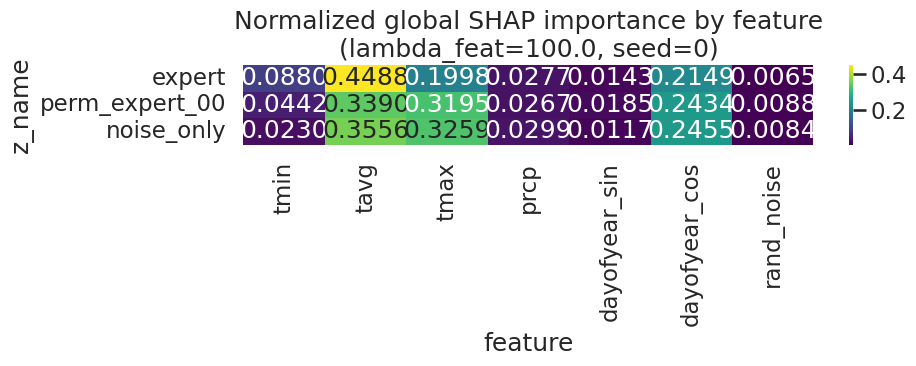

In [92]:
# Cell 33 - Heatmap of normalized global SHAP importance by feature
plt.figure(figsize=(10, max(4, 0.4 * len(selected_shap_z_names))))
sns.heatmap(shap_global_pivot, annot=True, fmt=".4f", cmap="viridis")
plt.title(
    f"Normalized global SHAP importance by feature\n"
    f"(lambda_feat={selected_shap_lambda}, seed={selected_shap_seed})"
)
plt.xlabel("feature")
plt.ylabel("z_name")
plt.tight_layout()
plt.show()

## Direct comparison: SHAP importance vs pseudo-label $z$

The next plots compare, for selected runs:

- the **normalized global SHAP importance**
- the **normalized pseudo-label vector $z$**

This gives a direct visual check of whether the global SHAP attribution profile is broadly consistent with the intended pseudo-label prior.

In [93]:
# Cell 34 - Table version of normalized SHAP importance vs normalized z for the selected comparison runs
for z_name in comparison_plot_z_names:
    run_id = f"z={z_name}|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"

    sub = (
        shap_feature_df[shap_feature_df["run_id"] == run_id][
            [
                "feature",
                "mean_abs_shap_norm",
                "z_norm",
                "diff_norm_shap_minus_z",
                "g_final",
            ]
        ]
        .sort_values("mean_abs_shap_norm", ascending=False)
        .reset_index(drop=True)
    )

    print(
        f"\nNormalized SHAP-vs-z comparison table "
        f"for z={z_name}, lambda_feat={selected_shap_lambda}, seed={selected_shap_seed}"
    )
    display(sub.round(4))


Normalized SHAP-vs-z comparison table for z=expert, lambda_feat=100.0, seed=0


,feature,mean_abs_shap_norm,z_norm,diff_norm_shap_minus_z,g_final
0,tavg,0.4488,0.2703,0.1785,0.9026
1,dayofyear_cos,0.2149,0.0811,0.1338,0.3605
2,tmax,0.1998,0.2703,-0.0704,0.8905
3,tmin,0.0880,0.1892,-0.1012,0.7014
4,prcp,0.0277,0.1081,-0.0804,0.4142
5,dayofyear_sin,0.0143,0.0811,-0.0668,0.3441
6,rand_noise,0.0065,0.0000,0.0065,0.2696



Normalized SHAP-vs-z comparison table for z=perm_expert_00, lambda_feat=100.0, seed=0


,feature,mean_abs_shap_norm,z_norm,diff_norm_shap_minus_z,g_final
0,tavg,0.3390,0.0811,0.2579,0.3791
1,tmax,0.3195,0.1081,0.2114,0.4449
2,dayofyear_cos,0.2434,0.1892,0.0542,0.6999
3,tmin,0.0442,0.2703,-0.2261,0.9086
4,prcp,0.0267,0.0000,0.0267,0.2708
5,dayofyear_sin,0.0185,0.0811,-0.0626,0.3448
6,rand_noise,0.0088,0.2703,-0.2614,0.9156



Normalized SHAP-vs-z comparison table for z=noise_only, lambda_feat=100.0, seed=0


,feature,mean_abs_shap_norm,z_norm,diff_norm_shap_minus_z,g_final
0,tavg,0.3556,0.0,0.3556,0.2839
1,tmax,0.3259,0.0,0.3259,0.2846
2,dayofyear_cos,0.2455,0.0,0.2455,0.2723
3,prcp,0.0299,0.0,0.0299,0.2708
4,tmin,0.0230,0.0,0.0230,0.2702
5,dayofyear_sin,0.0117,0.0,0.0117,0.2672
6,rand_noise,0.0084,1.0,-0.9916,0.9152


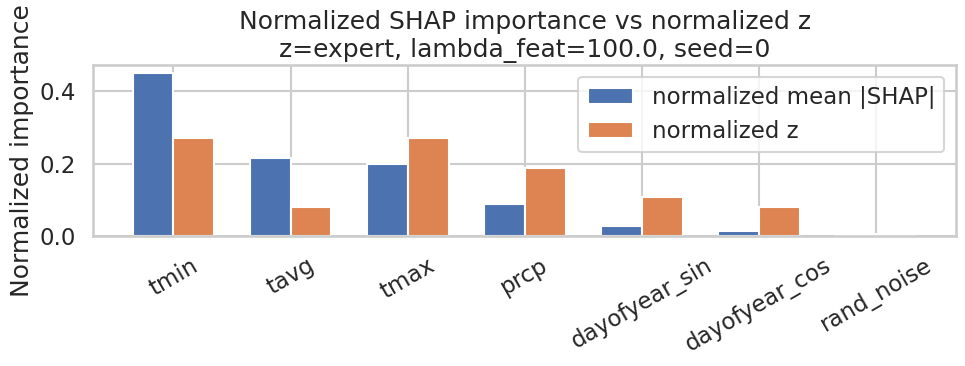

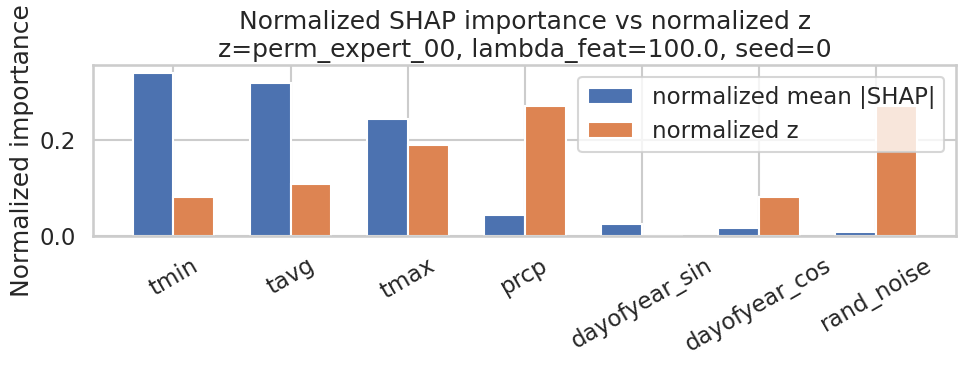

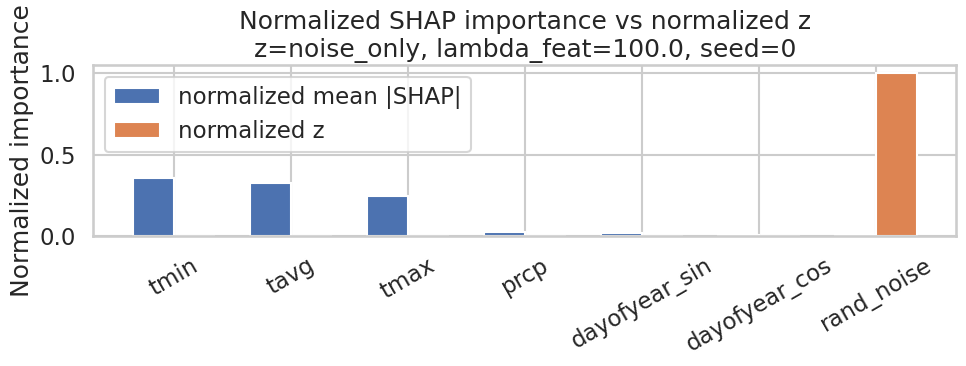

In [94]:
# Cell 35 - Bar plots comparing normalized SHAP importance to normalized z
for z_name in comparison_plot_z_names:
    run_id = f"z={z_name}|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"
    sub = shap_feature_df[shap_feature_df["run_id"] == run_id].copy()

    x = np.arange(len(feature_cols))
    w = 0.35

    plt.figure(figsize=(10, 4))
    plt.bar(x - w / 2, sub["mean_abs_shap_norm"], width=w, label="normalized mean |SHAP|")
    plt.bar(x + w / 2, sub["z_norm"], width=w, label="normalized z")
    plt.xticks(x, feature_cols, rotation=30)
    plt.ylabel("Normalized importance")
    plt.title(
        f"Normalized SHAP importance vs normalized z\n"
        f"z={z_name}, lambda_feat={selected_shap_lambda}, seed={selected_shap_seed}"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

## Familiar SHAP plots for one representative run

The next two plots are the most familiar SHAP visualizations:

1. **Global SHAP bar plot**  
   mean absolute SHAP importance

2. **SHAP beeswarm plot**  
   the distribution of local SHAP values across the explained samples

By default, these are shown for:

- `z_name = representative_shap_run_name`
- `lambda_feat = selected_shap_lambda`
- `seed = selected_shap_seed`

In [95]:
# Cell 36 - Table version of the representative SHAP run
representative_run_id = (
    f"z={representative_shap_run_name}|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"
)

rep_feature_table = (
    shap_feature_df[shap_feature_df["run_id"] == representative_run_id][
        [
            "feature",
            "mean_abs_shap",
            "mean_abs_shap_norm",
            "z",
            "z_norm",
            "g_final",
            "diff_norm_shap_minus_z",
        ]
    ]
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(rep_feature_table.round(4))

,feature,mean_abs_shap,mean_abs_shap_norm,z,z_norm,g_final,diff_norm_shap_minus_z
0,tavg,4.5179,0.4488,1.0,0.2703,0.9026,0.1785
1,dayofyear_cos,2.1638,0.2149,0.3,0.0811,0.3605,0.1338
2,tmax,2.0119,0.1998,1.0,0.2703,0.8905,-0.0704
3,tmin,0.8861,0.0880,0.7,0.1892,0.7014,-0.1012
4,prcp,0.2790,0.0277,0.4,0.1081,0.4142,-0.0804
5,dayofyear_sin,0.1438,0.0143,0.3,0.0811,0.3441,-0.0668
6,rand_noise,0.0651,0.0065,0.0,0.0000,0.2696,0.0065


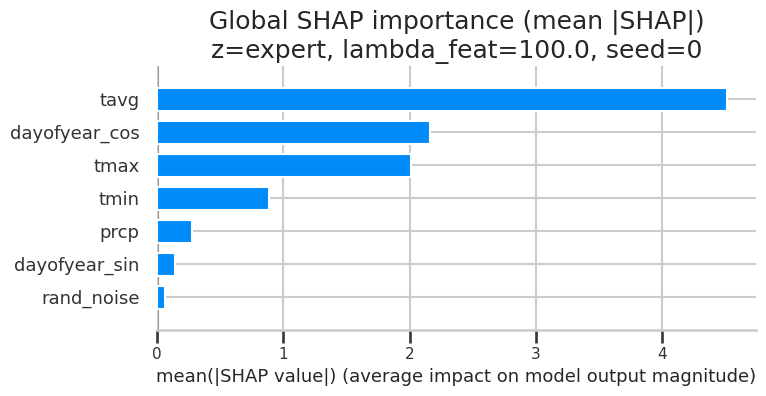

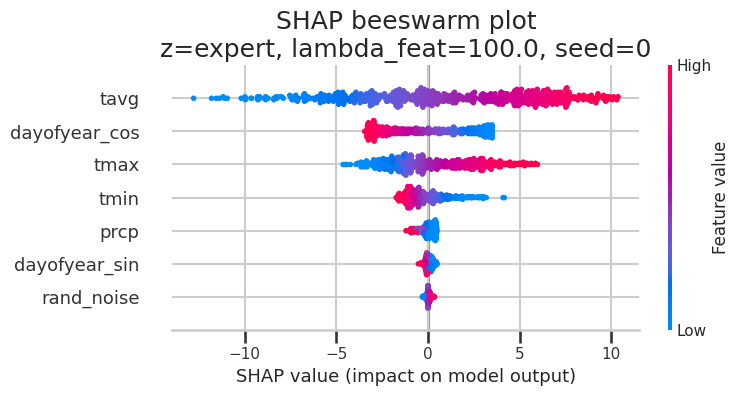

In [96]:
# Cell 37 - Familiar SHAP bar and beeswarm plots for one representative run
representative_run_id = (
    f"z={representative_shap_run_name}|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"
)
assert representative_run_id in shap_store, f"Missing SHAP artifact for {representative_run_id}"
rep = shap_store[representative_run_id]

plt.figure(figsize=(10, 4))
shap.summary_plot(
    rep["shap_values"],
    rep["X_explain_df"],
    feature_names=feature_cols,
    plot_type="bar",
    max_display=len(feature_cols),
    show=False,
)
plt.title(
    f"Global SHAP importance (mean |SHAP|)\n"
    f"z={representative_shap_run_name}, lambda_feat={selected_shap_lambda}, seed={selected_shap_seed}"
)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
shap.summary_plot(
    rep["shap_values"],
    rep["X_explain_df"],
    feature_names=feature_cols,
    max_display=len(feature_cols),
    show=False,
)
plt.title(
    f"SHAP beeswarm plot\n"
    f"z={representative_shap_run_name}, lambda_feat={selected_shap_lambda}, seed={selected_shap_seed}"
)
plt.tight_layout()
plt.show()

In [97]:
# Cell 37a - Summary statistics table for the representative SHAP beeswarm plot
rep_shap_values = np.asarray(rep["shap_values"], dtype=np.float64)

rep_distribution_table = (
    pd.DataFrame(
        {
            "feature": feature_cols,
            "mean_shap": rep_shap_values.mean(axis=0),
            "mean_abs_shap": np.abs(rep_shap_values).mean(axis=0),
            "std_shap": rep_shap_values.std(axis=0),
            "min_shap": rep_shap_values.min(axis=0),
            "max_shap": rep_shap_values.max(axis=0),
        }
    )
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(rep_distribution_table.round(4))

,feature,mean_shap,mean_abs_shap,std_shap,min_shap,max_shap
0,tavg,1.0338,4.5179,5.2346,-12.7984,10.3718
1,dayofyear_cos,-0.0996,2.1638,2.3886,-3.4596,3.5057
2,tmax,0.2462,2.0119,2.3683,-4.6380,5.9714
3,tmin,-0.2265,0.8861,1.0497,-1.7428,4.1608
4,prcp,0.0177,0.2790,0.3588,-1.2045,0.4759
5,dayofyear_sin,0.0535,0.1438,0.1707,-0.5316,0.4987
6,rand_noise,0.0072,0.0651,0.0911,-0.3095,0.3482


In [98]:
# Cell 38 - Save SHAP outputs

if RUN_SHAP:
    shap_results_dir = results_dir / "shap"
    shap_results_dir.mkdir(parents=True, exist_ok=True)

    shap_run_df.to_csv(shap_results_dir / "shap_run_summary.csv", index=False)
    shap_feature_df.to_csv(shap_results_dir / "shap_feature_importance.csv", index=False)
    shap_global_pivot.to_csv(shap_results_dir / "shap_global_importance_pivot.csv")

    shap_config = {
        "selected_shap_lambda": float(selected_shap_lambda),
        "selected_shap_seed": int(selected_shap_seed),
        "selected_shap_z_names": list(selected_shap_z_names),
        "comparison_plot_z_names": list(comparison_plot_z_names),
        "representative_shap_run_name": representative_shap_run_name,
        "shap_background_size": int(shap_background_size),
        "shap_method_preference": shap_method_preference,
        "shap_explain_split": shap_explain_split,
    }
    with open(shap_results_dir / "shap_config.json", "w") as fh:
        json.dump(shap_config, fh, indent=2)

    # Save baseline artifacts
    pd.DataFrame([baseline_record]).to_csv(shap_results_dir / "baseline_record.csv", index=False)
    baseline_shap_feature_df.to_csv(shap_results_dir / "baseline_shap_feature_importance.csv", index=False)
    baseline_occ_feature_df.to_csv(shap_results_dir / "baseline_occlusion_importance.csv", index=False)

    pd.DataFrame(
        {"feature": feature_cols, "baseline_shap_norm": baseline_shap_vector}
    ).to_csv(shap_results_dir / "baseline_shap_vector.csv", index=False)

    pd.DataFrame(
        {"feature": feature_cols, "baseline_occ_importance": baseline_occ_imp}
    ).to_csv(shap_results_dir / "baseline_occ_vector.csv", index=False)

    # Save exact per-run artifacts
    for run_id, artifact in shap_store.items():
        safe_name = (
            run_id.replace("|", "__")
            .replace("=", "_")
            .replace(".", "p")
        )
        run_dir = shap_results_dir / safe_name
        run_dir.mkdir(parents=True, exist_ok=True)

        np.save(run_dir / "shap_values.npy", artifact["shap_values"])
        np.save(run_dir / "X_explain.npy", artifact["X_explain"])
        np.save(run_dir / "z.npy", artifact["z"])
        np.save(run_dir / "z_norm.npy", artifact["z_norm"])
        np.save(run_dir / "g_init.npy", artifact["g_init"])
        np.save(run_dir / "g_final.npy", artifact["g_final"])
        np.save(run_dir / "shap_importance_mean_abs.npy", artifact["shap_importance_mean_abs"])
        np.save(run_dir / "shap_importance_mean_abs_norm.npy", artifact["shap_importance_mean_abs_norm"])

        with open(run_dir / "meta.json", "w") as fh:
            json.dump(
                {
                    "run_id": run_id,
                    "expected_value": float(artifact["shap_expected_value"]),
                    "feature_cols": list(feature_cols),
                },
                fh,
                indent=2,
            )

    print("Saved SHAP outputs to:", shap_results_dir)

else:
    print("RUN_SHAP=False, so SHAP outputs were not rewritten.")

RUN_SHAP=False, so SHAP outputs were not rewritten.


## Summary of the SHAP section

This supplementary section adds a familiar post-hoc attribution view to the main $z$-sweep results.

It is useful for checking whether:

- the expert prior leads to a SHAP importance profile that broadly agrees with the intended feature-importance pattern,
- permuted or adversarial priors lead to different global attribution profiles,
- and the SHAP-based global importance agrees or disagrees with the gate-based parameter-level interpretation.

Because SHAP is a post-hoc attribution method and the weather features are correlated, these results should be interpreted as **supplementary evidence**, not as the sole measure of feature usage.

In [99]:
# Cell 40 - Final compact SHAP summary display
display(
    shap_run_df[
        [
            "z_name",
            "lambda_feat",
            "test_rmse",
            "gate_cos",
            "gate_spearman",
            "shap_cos",
            "shap_spearman",
            "feat_loss_reduction_frac",
            "gate_move_l2",
        ]
    ].round(4)
)

,z_name,lambda_feat,test_rmse,gate_cos,gate_spearman,shap_cos,shap_spearman,feat_loss_reduction_frac,gate_move_l2
0,expert,100.0,2.2984,0.9825,0.9820,0.8628,0.6910,0.9139,0.8100
1,perm_expert_00,100.0,2.3193,0.9824,0.9820,0.5156,-0.1818,0.9147,0.7958
2,noise_only,100.0,2.3064,0.8055,0.6124,0.0154,-0.6124,0.8595,1.1327


In [100]:
# Cell 41 - direct baseline-vs-gated SHAP comparison

baseline_vs_gated_rows = []
baseline_vs_gated_feature_frames = []

for z_name in selected_shap_z_names:
    run_id = f"z={z_name}|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"

    gated_imp = np.asarray(
        shap_store[run_id]["shap_importance_mean_abs_norm"],
        dtype=np.float64,
    )

    comp = compute_alignment_metrics(baseline_shap_vector, gated_imp)

    gated_test_rmse = float(
        shap_run_df.loc[shap_run_df["run_id"] == run_id, "test_rmse"].iloc[0]
    )

    baseline_vs_gated_rows.append(
        {
            "run_id": run_id,
            "z_name": z_name,
            "z_family": z_family_of(z_name),
            "baseline_test_rmse": float(baseline_record["test_rmse"]),
            "gated_test_rmse": gated_test_rmse,
            "shap_l2_baseline_vs_gated": comp.l2_distance,
            "shap_cos_baseline_vs_gated": comp.cosine_similarity,
            "shap_spearman_baseline_vs_gated": comp.spearman_rank_corr,
        }
    )

    gated_feature_df = (
        shap_feature_df.loc[
            shap_feature_df["run_id"] == run_id,
            ["feature", "mean_abs_shap_norm"]
        ]
        .rename(columns={"mean_abs_shap_norm": "gated_mean_abs_shap_norm"})
        .copy()
    )

    baseline_feature_df = baseline_shap_feature_df.rename(
        columns={"mean_abs_shap_norm": "baseline_mean_abs_shap_norm"}
    )[["feature", "baseline_mean_abs_shap_norm"]].copy()

    merged = baseline_feature_df.merge(gated_feature_df, on="feature", how="inner")
    merged["run_id"] = run_id
    merged["z_name"] = z_name
    merged["delta_gated_minus_baseline"] = (
        merged["gated_mean_abs_shap_norm"] - merged["baseline_mean_abs_shap_norm"]
    )

    baseline_vs_gated_feature_frames.append(merged)

baseline_vs_gated_df = pd.DataFrame(baseline_vs_gated_rows)
baseline_vs_gated_feature_df = pd.concat(
    baseline_vs_gated_feature_frames,
    ignore_index=True,
)

print("Run-level baseline vs gated SHAP comparison:")
display(baseline_vs_gated_df.round(4))

print("Feature-level baseline vs gated SHAP comparison:")
display(baseline_vs_gated_feature_df.round(4))

Run-level baseline vs gated SHAP comparison:


,run_id,z_name,z_family,baseline_test_rmse,gated_test_rmse,shap_l2_baseline_vs_gated,shap_cos_baseline_vs_gated,shap_spearman_baseline_vs_gated
0,z=expert|lambda=100|seed=0,expert,expert,2.3235,2.2984,0.1324,0.9703,0.9286
1,z=perm_expert_00|lambda=100|seed=0,perm_expert_00,permuted_expert,2.3235,2.3193,0.0551,0.9948,0.9643
2,z=noise_only|lambda=100|seed=0,noise_only,structured,2.3235,2.3064,0.0675,0.9933,0.8929


Feature-level baseline vs gated SHAP comparison:


,feature,baseline_mean_abs_shap_norm,gated_mean_abs_shap_norm,run_id,z_name,delta_gated_minus_baseline
0,tavg,0.3531,0.4488,z=expert|lambda=100|seed=0,expert,0.0957
1,tmax,0.2723,0.1998,z=expert|lambda=100|seed=0,expert,-0.0725
2,dayofyear_cos,0.2460,0.2149,z=expert|lambda=100|seed=0,expert,-0.0311
3,tmin,0.0507,0.0880,z=expert|lambda=100|seed=0,expert,0.0373
4,dayofyear_sin,0.0418,0.0143,z=expert|lambda=100|seed=0,expert,-0.0275
5,prcp,0.0302,0.0277,z=expert|lambda=100|seed=0,expert,-0.0025
6,rand_noise,0.0058,0.0065,z=expert|lambda=100|seed=0,expert,0.0007
7,tavg,0.3531,0.3390,z=perm_expert_00|lambda=100|seed=0,perm_expert_00,-0.0141
8,tmax,0.2723,0.3195,z=perm_expert_00|lambda=100|seed=0,perm_expert_00,0.0472
9,dayofyear_cos,0.2460,0.2434,z=perm_expert_00|lambda=100|seed=0,perm_expert_00,-0.0026


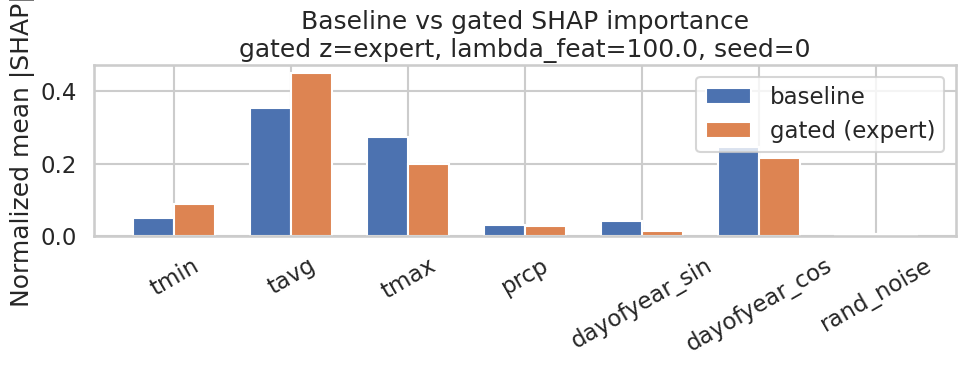

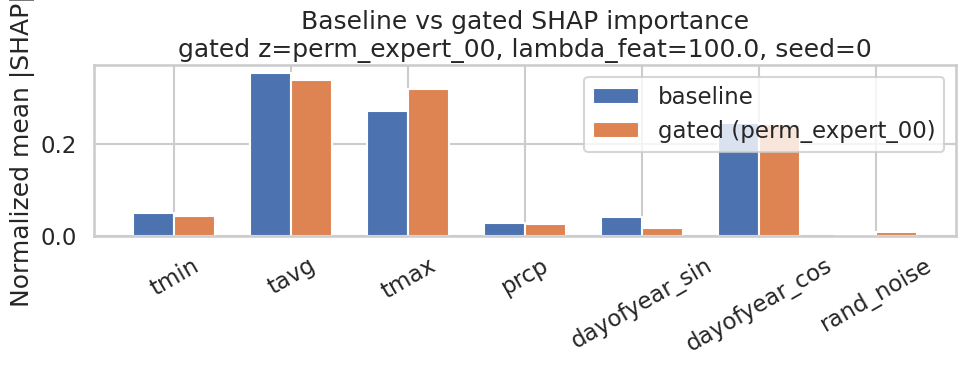

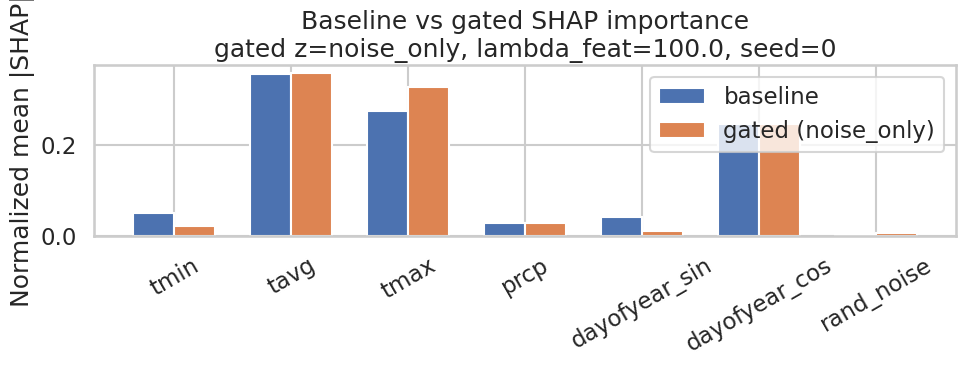

In [101]:
# Cell 42 - bar plots: baseline SHAP vs gated SHAP

for z_name in comparison_plot_z_names:
    run_id = f"z={z_name}|lambda={selected_shap_lambda:g}|seed={selected_shap_seed}"
    sub = baseline_vs_gated_feature_df[
        baseline_vs_gated_feature_df["run_id"] == run_id
    ].copy()

    sub = sub.set_index("feature").loc[feature_cols].reset_index()

    x = np.arange(len(feature_cols))
    w = 0.35

    plt.figure(figsize=(10, 4))
    plt.bar(x - w / 2, sub["baseline_mean_abs_shap_norm"], width=w, label="baseline")
    plt.bar(x + w / 2, sub["gated_mean_abs_shap_norm"], width=w, label=f"gated ({z_name})")
    plt.xticks(x, feature_cols, rotation=30)
    plt.ylabel("Normalized mean |SHAP|")
    plt.title(
        f"Baseline vs gated SHAP importance\n"
        f"gated z={z_name}, lambda_feat={selected_shap_lambda}, seed={selected_shap_seed}"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

In [102]:
# Cell 43 - combined SHAP heatmap including baseline

combined_shap_pivot = pd.concat(
    [
        pd.DataFrame(
            [baseline_shap_vector],
            index=["baseline"],
            columns=feature_cols,
        ),
        shap_global_pivot,
    ],
    axis=0,
)

display(combined_shap_pivot.round(4))

,tmin,tavg,tmax,prcp,dayofyear_sin,dayofyear_cos,rand_noise
baseline,0.0507,0.3531,0.2723,0.0302,0.0418,0.2460,0.0058
expert,0.0880,0.4488,0.1998,0.0277,0.0143,0.2149,0.0065
perm_expert_00,0.0442,0.3390,0.3195,0.0267,0.0185,0.2434,0.0088
noise_only,0.0230,0.3556,0.3259,0.0299,0.0117,0.2455,0.0084


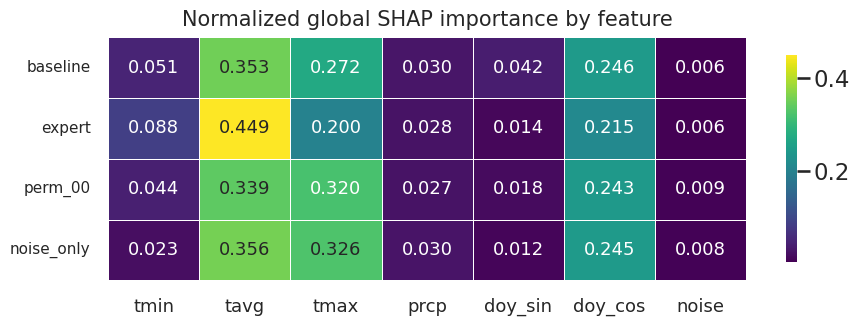

In [103]:
# Cell 44
plot_df = combined_shap_pivot.copy()
plot_df = plot_df.rename(
    columns={
        "dayofyear_sin": "doy_sin",
        "dayofyear_cos": "doy_cos",
        "rand_noise": "noise",
    },
    index={"perm_expert_00": "perm_00"},
)

fig, ax = plt.subplots(figsize=(9.5, 3.6))

sns.heatmap(
    plot_df,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 13},
    cbar_kws={"shrink": 0.85},
    ax=ax,
)

ax.set_title("Normalized global SHAP importance by feature", fontsize=15, pad=8)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=13, rotation=0)
ax.tick_params(axis="y", labelsize=11, rotation=0)

plt.tight_layout()
plt.savefig("../docs/figures/ch5_shap_heatmap.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [104]:
# Cell 45 - baseline SHAP alignment to selected z vectors

baseline_vs_z_rows = []

for z_name in selected_shap_z_names:
    z_np_cur = z_library[z_name].astype(np.float64)
    z_norm = z_np_cur / (z_np_cur.sum() + 1e-8)

    a = compute_alignment_metrics(baseline_shap_vector, z_norm)

    baseline_vs_z_rows.append(
        {
            "z_name": z_name,
            "z_family": z_family_of(z_name),
            "baseline_shap_l2_to_z": a.l2_distance,
            "baseline_shap_cos_to_z": a.cosine_similarity,
            "baseline_shap_spearman_to_z": a.spearman_rank_corr,
        }
    )

baseline_vs_z_df = pd.DataFrame(baseline_vs_z_rows)
display(baseline_vs_z_df.round(4))

,z_name,z_family,baseline_shap_l2_to_z,baseline_shap_cos_to_z,baseline_shap_spearman_to_z
0,expert,expert,0.2467,0.8775,0.7819
1,perm_expert_00,permuted_expert,0.4741,0.5271,-0.1273
2,noise_only,structured,1.1194,0.0112,-0.6124
